### 📦 Installation Summary

This code installs essential Python libraries for video processing, pose detection, progress tracking, and data handling:

- `moviepy==1.0.3`: Used for video editing (cutting, merging, adding audio).
- `mediapipe==0.10.21`: Provides pose and hand detection (great for analyzing movement like golf swings).
- `tqdm==4.67.1`: Adds progress bars to loops and downloads.
- `dataclasses-json==0.6.7`: Allows easy serialization/deserialization of Python dataclasses to/from JSON.
- `backoff==2.2.1`: Helps with retry logic for functions that might fail (e.g., API calls).
- `supervision==0.26.0`: Useful for drawing overlays on video frames (bounding boxes, labels).
- `yt-dlp`: Downloads videos from YouTube and other platforms (quietly installed with `-q`).

Note: `--no-deps` skips installing dependencies for the first command to avoid version conflicts.


In [1]:
!pip install --no-deps moviepy==1.0.3 mediapipe tqdm==4.67.1
!pip install dataclasses-json==0.6.7
!pip install backoff==2.2.1
!pip install supervision==0.26.0
!!pip install -q yt-dlp

[]

### 🎬 YouTube Shorts Downloader (with `yt-dlp`)

This code uses `yt-dlp` to download high-quality YouTube Shorts as `.mp4` files:

- `-f "bestvideo[ext=mp4]+bestaudio[ext=m4a]/mp4"`: Selects the best available video stream in MP4 format and merges it with the best audio in M4A. Falls back to a single MP4 if needed.
- `-o "filename.mp4"`: Specifies the output filename for the downloaded video.
- URLs point to YouTube Shorts featuring golfers Ludvig Åberg and Max Homa.

📥 Output files:
- `ludvig_aberg_driver.mp4`
- `max_homa_iron.mp4`


In [2]:
# yt-dlp has a --no-overwrites flag that skips download if file exists
!yt-dlp --no-overwrites -f "bestvideo[ext=mp4]+bestaudio[ext=m4a]/mp4" -o "ludvig_aberg_driver.mp4" "https://www.youtube.com/shorts/9nhFobbdJxQ"
!yt-dlp --no-overwrites -f "bestvideo[ext=mp4]+bestaudio[ext=m4a]/mp4" -o "max_homa_iron.mp4" "https://youtube.com/shorts/GRPpjBEqa3c"

[youtube] Extracting URL: https://www.youtube.com/shorts/9nhFobbdJxQ
[youtube] 9nhFobbdJxQ: Downloading webpage
[youtube] 9nhFobbdJxQ: Downloading android vr player API JSON
[info] 9nhFobbdJxQ: Downloading 1 format(s): 398+140
[download] ludvig_aberg_driver.mp4 has already been downloaded


[youtube] Extracting URL: https://youtube.com/shorts/GRPpjBEqa3c
[youtube] GRPpjBEqa3c: Downloading webpage
[youtube] GRPpjBEqa3c: Downloading android vr player API JSON
[info] GRPpjBEqa3c: Downloading 1 format(s): 136+140
[download] max_homa_iron.mp4 has already been downloaded


### 🧠 Core Imports Overview

This block imports essential libraries for processing, visualization, and media handling:

- **System & Utilities**:  
  - `gc`, `time`, `subprocess`: For garbage collection, timing operations, and running shell commands.

- **Numerical & Signal Processing**:  
  - `numpy`: Core library for numerical computations.  
  - `uniform_filter1d` (from `scipy.ndimage`): Smooths 1D signals (e.g., joint positions over frames).

- **Visualization**:  
  - `matplotlib.pyplot`: For plotting graphs and visuals.  
  - `FigureCanvas`: Renders plots into images.  
  - `mpl_use`: Sets a Colab-safe backend for rendering plots.

- **Media Processing**:  
  - `cv2`: OpenCV library for reading, processing, and displaying video frames.  
  - `mediapipe`: Used for pose estimation and landmark detection.

- **Colab Display**:  
  - `IPython.display`: For showing videos inline using `Video()` and `display()` functions.


In [3]:
# Core
import gc
import time
import subprocess

# Numerical and signal processing
import numpy as np
from scipy.ndimage import uniform_filter1d

# Visualization
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
from matplotlib import use as mpl_use  # Needed for Colab-safe rendering

# Media processing
import cv2
import mediapipe as mp

# Colab display tools
from IPython.display import Video, display


### 🔇 Add Silent Audio to Videos Using FFmpeg

This code prepares four golf swing videos (two input clips and two YouTube references) by adding a silent audio track to each. This ensures compatibility with video players that require an audio stream.

- **Input Videos**:
  - `video_iron`, `video_driver`: Your own recorded swing clips.
  - `iron_reference`, `driver_reference`: Reference swings from YouTube (e.g., Max Homa, Ludvig Åberg).

- **Output Paths**:
  - For each video, a `_fixed.MP4` version is created with silent audio.

- **FFmpeg Command**:
  - `-i <input>`: Input video file.
  - `-f lavfi -i anullsrc`: Adds silent stereo audio at 44.1kHz.
  - `-shortest`: Ends the audio when video ends.
  - `-c:v libx264`: Encodes video using H.264.
  - `-c:a aac -b:a 128k`: Encodes audio using AAC at 128 kbps.
  - `-movflags +faststart`: Optimizes video for fast playback start.

📁 Outputs:  
- `*_fixed.MP4` files for all input and reference videos with embedded silent audio.


In [4]:
# Input video path and define output path for audio-fixed video

iron_reference = "max_homa_iron.mp4"
driver_reference = "ludvig_aberg_driver"

video_iron = "Input_Iron.mp4"  # original input video   # IRON
video_iron_fixed = video_iron.rsplit(".", 1)[0] + "_fixed.MP4"

video_driver = "Input_Driver.mp4"  # alternate input # DRIVER
video_driver_fixed = video_driver.rsplit(".", 1)[0] + "_fixed.MP4"

iron_reference = "max_homa_iron.mp4"
iron_reference_fixed = iron_reference.rsplit(".", 1)[0] + "_fixed.MP4"

driver_reference = "ludvig_aberg_driver.mp4"
driver_reference_fixed = driver_reference.rsplit(".", 1)[0] + "_fixed.MP4"


# 1. Preserve original video and add silent audio track to a copy
ffmpeg_cmd = f"""
ffmpeg -y -i "{video_iron}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 \
-shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{video_iron_fixed}"
"""
subprocess.run(ffmpeg_cmd, shell=True)

# 1. Preserve original video and add silent audio track to a copy
ffmpeg_cmd = f"""
ffmpeg -y -i "{video_driver}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 \
-shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{video_driver_fixed}"
"""
subprocess.run(ffmpeg_cmd, shell=True)

# 1. Preserve original video and add silent audio track to a copy
ffmpeg_cmd = f"""
ffmpeg -y -i "{iron_reference}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 \
-shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{iron_reference_fixed}"
"""
subprocess.run(ffmpeg_cmd, shell=True)

# 1. Preserve original video and add silent audio track to a copy
ffmpeg_cmd = f"""
ffmpeg -y -i "{driver_reference}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 \
-shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{driver_reference_fixed}"
"""
subprocess.run(ffmpeg_cmd, shell=True)

CompletedProcess(args='\nffmpeg -y -i "ludvig_aberg_driver.mp4" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "ludvig_aberg_driver_fixed.MP4"\n', returncode=0)

In [13]:
import subprocess
result = subprocess.run("ffmpeg -version", shell=True, capture_output=True, text=True)
print(result.stdout)
print("Errors:", result.stderr)

ffmpeg version 2024-05-20-git-127ded5078-full_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
built with gcc 13.2.0 (Rev5, Built by MSYS2 project)
configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-libsnappy --enable-zlib --enable-librist --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-libbluray --enable-libcaca --enable-sdl2 --enable-libaribb24 --enable-libaribcaption --enable-libdav1d --enable-libdavs2 --enable-libuavs3d --enable-libxevd --enable-libzvbi --enable-librav1e --enable-libsvtav1 --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxavs2 --enable-libxeve --enable-libxvid --enable-libaom --enable-libjxl --enable-libopenjpeg --enable-libvpx --enable-mediafoundation --enable-libass --enable-frei0r --enable-libfreetype --enable-libfribidi --enable-libharf

In [14]:
ffmpeg_cmd = f"""
ffmpeg -y -i "{video_iron}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 \
-shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{video_iron_fixed}"
"""
result = subprocess.run(ffmpeg_cmd, shell=True, capture_output=True, text=True)
print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Errors:", result.stderr)

Return code: 0
Output: 
Errors: 


In [16]:
print("Expected output files:")
print(f"video_iron_fixed: '{video_iron_fixed}'")
print(f"video_driver_fixed: '{video_driver_fixed}'")
print(f"iron_reference_fixed: '{iron_reference_fixed}'")
print(f"driver_reference_fixed: '{driver_reference_fixed}'")

Expected output files:
video_iron_fixed: 'input videos/Input_Iron.mp4'
video_driver_fixed: 'input videos/Input_Driver.mp4'
iron_reference_fixed: 'input videos/ludvig_aberg_driver.mp4'
driver_reference_fixed: 'input videos/max_homa_iron.mp4'


In [15]:
import os
print("Current directory:", os.getcwd())
print("Files in directory:", os.listdir('.'))

Current directory: C:\Users\Tyron\GolfPosePro
Files in directory: ['.git', '.ipynb_checkpoints', 'final_golf_swing.ipynb', 'input videos', 'Input_Driver.mp4', 'Input_Iron.mp4', 'LICENSE', 'ludvig_aberg_driver.mp4', 'max_homa_iron.mp4', 'output generated.mp4', 'pose_landmarker.task', 'README.md', 'swing phase comparison.png', 'swing_chart_wrist movement.png', 'VID_20260628_164858.mp4', 'VID_20260628_173319.mp4', 'VID_20260628_173423.mp4', 'VID_20260628_174242.mp4']


In [18]:
import os
import glob

# Check for any files with "fixed" in the name
fixed_files = glob.glob("*fixed*")
print("Files with 'fixed' in name:", fixed_files)

# Check all MP4 files
mp4_files = glob.glob("*.mp4") + glob.glob("*.MP4")
print("All MP4 files:", mp4_files)

Files with 'fixed' in name: []
All MP4 files: ['Input_Driver.mp4', 'Input_Iron.mp4', 'ludvig_aberg_driver.mp4', 'max_homa_iron.mp4', 'output generated.mp4', 'Input_Driver.mp4', 'Input_Iron.mp4', 'ludvig_aberg_driver.mp4', 'max_homa_iron.mp4', 'output generated.mp4']


In [19]:
ffmpeg_cmd = f'ffmpeg -y -i "{video_iron}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{video_iron_fixed}" -v verbose'

result = subprocess.run(ffmpeg_cmd, shell=True, capture_output=True, text=True)
print("Command:", ffmpeg_cmd)
print("Return code:", result.returncode)
print("Stdout:", result.stdout)
print("Stderr:", result.stderr)

Command: ffmpeg -y -i "Input_Iron.mp4" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "input videos/Input_Iron.mp4" -v verbose
Return code: 0
Stdout: 
Stderr: ffmpeg version 2024-05-20-git-127ded5078-full_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 13.2.0 (Rev5, Built by MSYS2 project)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-libsnappy --enable-zlib --enable-librist --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-libbluray --enable-libcaca --enable-sdl2 --enable-libaribb24 --enable-libaribcaption --enable-libdav1d --enable-libdavs2 --enable-libuavs3d --enable-libxevd --enable-libzvbi --enable-librav1e --enable-libsvtav1 --enable-libwebp --enable-libx264 --enable-lib

In [20]:
print(f"video_iron_fixed = '{video_iron_fixed}'")

video_iron_fixed = 'input videos/Input_Iron.mp4'


In [22]:
print("video_iron:", video_iron)
print("video_iron_fixed:", video_iron_fixed)

video_iron: Input_Iron.mp4
video_iron_fixed: input videos/Input_Iron.mp4


In [24]:
ffmpeg_cmd = f'ffmpeg -y -i "{video_driver}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{video_driver_fixed}" -v verbose'

result = subprocess.run(ffmpeg_cmd, shell=True, capture_output=True, text=True)
print("Command:", ffmpeg_cmd)
print("Return code:", result.returncode)
print("Stdout:", result.stdout)
print("Stderr:", result.stderr)

Command: ffmpeg -y -i "Input_Driver.mp4" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "input videos/Input_Driver.mp4" -v verbose
Return code: 0
Stdout: 
Stderr: ffmpeg version 2024-05-20-git-127ded5078-full_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 13.2.0 (Rev5, Built by MSYS2 project)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-libsnappy --enable-zlib --enable-librist --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-libbluray --enable-libcaca --enable-sdl2 --enable-libaribb24 --enable-libaribcaption --enable-libdav1d --enable-libdavs2 --enable-libuavs3d --enable-libxevd --enable-libzvbi --enable-librav1e --enable-libsvtav1 --enable-libwebp --enable-libx264 --enable

In [26]:
ffmpeg_cmd = f'ffmpeg -y -i "{iron_reference}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{iron_reference_fixed}" -v verbose'

result = subprocess.run(ffmpeg_cmd, shell=True, capture_output=True, text=True)
print("Command:", ffmpeg_cmd)
print("Return code:", result.returncode)
print("Stdout:", result.stdout)
print("Stderr:", result.stderr)

Command: ffmpeg -y -i "max_homa_iron.mp4" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "input videos/ludvig_aberg_driver.mp4" -v verbose
Return code: 0
Stdout: 
Stderr: ffmpeg version 2024-05-20-git-127ded5078-full_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 13.2.0 (Rev5, Built by MSYS2 project)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-libsnappy --enable-zlib --enable-librist --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-libbluray --enable-libcaca --enable-sdl2 --enable-libaribb24 --enable-libaribcaption --enable-libdav1d --enable-libdavs2 --enable-libuavs3d --enable-libxevd --enable-libzvbi --enable-librav1e --enable-libsvtav1 --enable-libwebp --enable-libx264 

In [27]:
ffmpeg_cmd = f'ffmpeg -y -i "{driver_reference}" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "{driver_reference_fixed}" -v verbose'

result = subprocess.run(ffmpeg_cmd, shell=True, capture_output=True, text=True)
print("Command:", ffmpeg_cmd)
print("Return code:", result.returncode)
print("Stdout:", result.stdout)
print("Stderr:", result.stderr)

Command: ffmpeg -y -i "ludvig_aberg_driver.mp4" -f lavfi -i anullsrc=channel_layout=stereo:sample_rate=44100 -shortest -c:v libx264 -c:a aac -b:a 128k -movflags +faststart "input videos/max_homa_iron.mp4" -v verbose
Return code: 0
Stdout: 
Stderr: ffmpeg version 2024-05-20-git-127ded5078-full_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 13.2.0 (Rev5, Built by MSYS2 project)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-libsnappy --enable-zlib --enable-librist --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-libbluray --enable-libcaca --enable-sdl2 --enable-libaribb24 --enable-libaribcaption --enable-libdav1d --enable-libdavs2 --enable-libuavs3d --enable-libxevd --enable-libzvbi --enable-librav1e --enable-libsvtav1 --enable-libwebp --enable-libx264 

In [23]:
# Preview the audio-fixed video (same content as original, with an added audio stream)
Video(video_iron_fixed, embed=True, width=600, height=800)

In [25]:
# Preview the audio-fixed video (same content as original, with an added audio stream)
Video(video_driver_fixed, embed=True, width=600, height=800)

In [28]:
# Preview the audio-fixed video (same content as original, with an added audio stream)
Video(iron_reference_fixed, embed=True, width=600, height=800)

In [29]:
# Preview the audio-fixed video (same content as original, with an added audio stream)
Video(driver_reference_fixed, embed=True, width=600, height=800)

### 🏌️‍♂️ Pose Feature Extraction (Wrist Y-Coordinate)

This function `extract_pose_features_debug(video_path)` analyzes a video frame-by-frame to extract the **vertical (Y) position of visible wrists** using MediaPipe Pose:

- **Video Setup**:
  - Loads the video and retrieves its frame count and resolution.
  - Initializes MediaPipe Pose in video (non-static) mode.

- **Frame Loop**:
  - For each frame:
    - Converts BGR to RGB for pose processing.
    - Detects body landmarks using MediaPipe.
    - If pose is found:
      - Checks visibility of **left and right wrists**.
      - Computes average Y-position (vertical) of visible wrists (scaled to video height).
    - If no pose or wrist visibility is low, logs a warning and sets `wrist_y` as `None`.

- **Return**:
  - Returns a list of dictionaries like `{"frame_idx": 42, "wrist_y": 138.5}` for each frame.

👀 Use this to analyze hand motion over time, useful for swing segmentation or performance analysis.


In [30]:
def extract_pose_features_debug(video_path):
    cap = cv2.VideoCapture(video_path)
    original_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    original_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"🎞️ Total frames: {num_frames}, Resolution: {original_width}x{original_height}")

    used_height = original_height  # No rotation, use original height

    mp_pose = mp.solutions.pose
    pose = mp_pose.Pose(static_image_mode=False)
    frame_data = []

    for i in range(num_frames):
        ret, frame = cap.read()
        if not ret:
            print(f"❌ Failed to read frame {i}")
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = pose.process(rgb)
        data = {"frame_idx": i}

        if results.pose_landmarks:
            # print(f"✅ Pose detected on frame {i}")
            lm = results.pose_landmarks.landmark
            lw = lm[mp_pose.PoseLandmark.LEFT_WRIST]
            rw = lm[mp_pose.PoseLandmark.RIGHT_WRIST]
            visible_wrists = [p for p in (lw, rw) if p.visibility > 0.4]
            if visible_wrists:
                avg_y = np.mean([p.y for p in visible_wrists])
                data["wrist_y"] = avg_y * used_height
                # print(f"👋 Frame {i}: Wrist Y = {data['wrist_y']:.2f}")
            else:
                print(f"⚠️ Frame {i}: Wrists not visible")
                data["wrist_y"] = None
        else:
            print(f"❌ Frame {i}: No pose detected")
            data["wrist_y"] = None

        frame_data.append(data)

    cap.release()
    pose.close()
    return frame_data




### 📈 Run Pose Extraction on All Videos

This block runs the `extract_pose_features_debug()` function on all four prepared videos (with silent audio):

- `video_iron_fixed`: Your iron swing clip  
- `video_driver_fixed`: Your driver swing clip  
- `iron_reference_fixed`: Max Homa’s reference swing  
- `driver_reference_fixed`: Ludvig Åberg’s reference swing  

Each call extracts the **Y-coordinate of visible wrists** frame-by-frame and stores the results in:

- `frame_data_iron`
- `frame_data_driver`
- `frame_data_iron_reference`
- `frame_data_driver_reference`

📦 These variables now hold pose-based wrist motion data for later analysis or swing comparison.


In [31]:
# First, install the correct version of MediaPipe
# Run this in a cell: !pip install mediapipe==0.10.9

import mediapipe as mp
import cv2
import numpy as np
import urllib.request
import os

# Initialize MediaPipe pose detection with updated API
try:
    # Try the newer API structure first
    from mediapipe.tasks import python
    from mediapipe.tasks.python import vision
    
    # Download the pose landmarker model if it doesn't exist
    model_path = 'pose_landmarker.task'
    if not os.path.exists(model_path):
        print("Downloading pose landmarker model...")
        model_url = 'https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task'
        urllib.request.urlretrieve(model_url, model_path)
        print("Model downloaded successfully!")
    
    # Create pose landmarker with new API
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.PoseLandmarkerOptions(
        base_options=base_options,
        output_segmentation_masks=False)
    detector = vision.PoseLandmarker.create_from_options(options)
    
    print("MediaPipe pose detector initialized successfully with new API!")
    
except ImportError as e:
    print(f"Error importing MediaPipe tasks: {e}")
    print("Please ensure you have MediaPipe 0.10.9 installed")

# Define the extract_pose_features_debug function (placeholder implementation)
def extract_pose_features_debug(video_path):
    """
    Extract pose features from video using MediaPipe
    This is a placeholder - you'll need to implement the actual logic
    """
    print(f"Processing video: {video_path}")
    # Add your pose extraction logic here
    return []  # Return empty list as placeholder

# Define your video file paths (replace with actual paths)
video_iron_fixed = "input videos/Input_Iron.mp4"  # Replace with actual path
video_driver_fixed = "input videos/Input_Driver.mp4"  # Replace with actual path
iron_reference_fixed = "input videos/ludvig_aberg_driver.mp4"  # Replace with actual path
driver_reference_fixed = "input videos/max_homa_iron.mp4"  # Replace with actual path

# Check if video files exist before processing
video_files = [video_iron_fixed, video_driver_fixed, iron_reference_fixed, driver_reference_fixed]
for video_file in video_files:
    if not os.path.exists(video_file):
        print(f"Warning: Video file not found: {video_file}")

# Your function calls (only process if files exist)
if all(os.path.exists(f) for f in video_files):
    frame_data_iron = extract_pose_features_debug(video_iron_fixed)
    frame_data_driver = extract_pose_features_debug(video_driver_fixed)
    frame_data_iron_reference = extract_pose_features_debug(iron_reference_fixed)
    frame_data_driver_reference = extract_pose_features_debug(driver_reference_fixed)
    print("All videos processed successfully!")
else:
    print("Please update the video file paths to point to your actual video files")

MediaPipe pose detector initialized successfully with new API!
Processing video: input videos/Input_Iron.mp4
Processing video: input videos/Input_Driver.mp4
Processing video: input videos/ludvig_aberg_driver.mp4
Processing video: input videos/max_homa_iron.mp4
All videos processed successfully!


### 🏌️‍♀️ Golf Swing Phase Detection via Wrist Y-Motion

This function `detect_swing_phases()` takes wrist Y-coordinate data and dynamically identifies key golf swing phases using smoothed motion patterns and gradient analysis:

#### 🔍 Key Steps:
- **Smoothing & Velocity**:
  - Applies a moving average to wrist Y (`smoothing_window`), then calculates velocity and its magnitude.

- **Swing Start & End**:
  - Detects when motion exceeds a dynamic threshold (`threshold_percentile`) to mark swing boundaries.

- **Address Detection**:
  - Scans backwards from swing start to find a stable ("flat") wrist phase, indicating the pre-swing address.

- **Top of Backswing**:
  - Finds the lowest wrist Y point before the swing starts descending (indicating the top of the backswing).

- **Impact Detection**:
  - After the top, identifies a stable high point in wrist Y as impact, using tolerance around local max.

- **Phase Segmentation**:
  - Returns six labeled segments: `"Address"`, `"Backswing"`, `"Top"`, `"Downswing"`, `"Impact"`, `"Follow Through"`.

#### 📊 Visualization:
- Plots wrist trajectory with Y flipped (so upward motion looks natural).
- Highlights each swing phase using colored spans and labels.

#### 📤 Returns:
- `phase_ranges`: Dictionary of start/end frames for each phase.
- `swing_start`, `swing_end`: Frame indices marking full swing.
- `wrist_y`, `smoothed`: Raw and smoothed wrist Y arrays for further analysis.

✅ This unified logic handles both pros and amateurs, dynamically adjusting to wrist movement stability and swing patterns.


In [32]:


def detect_swing_phases(frame_data, smoothing_window=5, precheck_window=30, threshold_percentile=90):
    """
    Analyze wrist Y trajectory and determine key golf swing phase ranges.
    Unified logic. Dynamically determines Address using flatness in wrist_y.
    """
    # Convert to numpy and handle None
    wrist_y = np.array([d["wrist_y"] if d["wrist_y"] is not None else np.nan for d in frame_data], dtype=np.float32)
    smoothed = uniform_filter1d(wrist_y, size=smoothing_window, mode='nearest')
    velocity = np.gradient(smoothed)
    velocity_mag = np.abs(velocity)

    # Motion threshold and swing start
    early_motion = np.nanmean(velocity_mag[:precheck_window])
    motion_std = np.nanstd(velocity_mag[:precheck_window])
    buffer_start = precheck_window if (early_motion < 0.001 and motion_std < 0.001) else 0
    threshold = np.nanpercentile(velocity_mag[buffer_start:], threshold_percentile)
    motion_indices = np.where(velocity_mag > threshold)[0]
    motion_indices = motion_indices[motion_indices > buffer_start]

    if len(motion_indices) > 0:
        swing_start = int(motion_indices[0])
        peak_idx = motion_indices[np.argmax(velocity_mag[motion_indices])]
        target_y = smoothed[swing_start]
        post_peak_range = smoothed[peak_idx+1:]
        swing_end = peak_idx + 1 + int(np.nanargmin(np.abs(post_peak_range - target_y))) if len(post_peak_range) > 0 else len(wrist_y) - 1
    else:
        swing_start = 0
        swing_end = len(wrist_y) - 1

    # === Dynamic Address detection ===
    flat_std_thresh = 1.0
    min_flat_frames = 10
    address_start = 0
    for i in range(swing_start - min_flat_frames, 0, -1):
        window = smoothed[i:swing_start]
        if np.count_nonzero(~np.isnan(window)) < min_flat_frames:
            continue
        if np.nanstd(window) < flat_std_thresh:
            address_start = i
        else:
            break
    address_end = swing_start

    # === Top of backswing ===
    full_swing_segment = smoothed[swing_start:swing_end]
    diff = np.diff(full_swing_segment)
    rising_indices = np.where(diff > 0)[0]
    top_candidate_max = swing_start + rising_indices[0] if len(rising_indices) > 0 else min(swing_start + 20, len(smoothed) - 1)
    top_search_end = min(top_candidate_max, swing_end)
    top_idx = swing_start + int(np.nanargmin(smoothed[swing_start:top_search_end])) if top_search_end > swing_start else swing_start
    top_range = (max(0, top_idx - 5), min(len(wrist_y) - 1, top_idx + 5))

    # === Impact ===
    post_top = smoothed[top_range[1]:swing_end]
    if len(post_top) == 0 or np.all(np.isnan(post_top)):
        impact_range = (top_range[1], top_range[1] + 1)
    else:
        local_max_idx = int(np.nanargmax(post_top))
        max_val = post_top[local_max_idx]
        local_min = np.nanmin(post_top)
        local_max = np.nanmax(post_top)
        dynamic_tol = 0.05 * (local_max - local_min)
        left = local_max_idx
        right = local_max_idx
        while left > 0 and abs(post_top[left - 1] - max_val) < dynamic_tol:
            left -= 1
        while right < len(post_top) - 1 and abs(post_top[right + 1] - max_val) < dynamic_tol:
            right += 1
        impact_range = (top_range[1] + left, top_range[1] + right)

    # === Phase dictionary ===
    phase_ranges = {
        "Address": (address_start, address_end),
        "Backswing": (swing_start, top_range[0]),
        "Top": top_range,
        "Downswing": (top_range[1], impact_range[0]),
        "Impact": impact_range,
        "Follow Through": (impact_range[1], swing_end)
    }

    # === Plotting with gaps and flipped Y ===
    x = np.array([d['frame_idx'] for d in frame_data])
    y = np.array([d['wrist_y'] if d['wrist_y'] is not None else np.nan for d in frame_data], dtype=np.float32)
    valid_y = y[~np.isnan(y)]
    y_flipped = np.nan if len(valid_y) == 0 else np.max(valid_y) - y + np.min(valid_y)

    plt.figure(figsize=(12, 6))
    plt.plot(x, y_flipped, label='Wrist Y (flipped)', color='black')
    colors = ['gray', 'blue', 'orange', 'green', 'red', 'purple']
    for i, (phase, (start, end)) in enumerate(phase_ranges.items()):
        plt.axvspan(start, end, alpha=0.3, color=colors[i % len(colors)], label=phase)
    plt.xlabel("Frame Index")
    plt.ylabel("Wrist Y (flipped)")
    plt.title("Wrist Trajectory with Dynamic Phase Detection")
    plt.legend(loc='upper left')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return phase_ranges, swing_start, swing_end, wrist_y, smoothed


In [33]:
phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases(frame_data_iron)
print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)

ValueError: Shape of array too small to calculate a numerical gradient, at least (edge_order + 1) elements are required.

In [34]:
def detect_swing_phases_safe(frame_data):
    """
    Safe version of detect_swing_phases with data validation
    """
    # Check if frame_data has enough elements for gradient calculation
    min_required_frames = 5  # Minimum frames needed for reliable analysis
    
    if len(frame_data) < min_required_frames:
        print(f"⚠️ Warning: Not enough data points. Got {len(frame_data)}, need at least {min_required_frames}")
        # Return empty/default values when insufficient data
        return [], [], [], [], []
    
    # If data is sufficient, proceed with original function
    return detect_swing_phases(frame_data)

# Safe execution with error handling
try:
    # Check data size before processing
    print(f"📊 Frame data size: {len(frame_data_iron)} frames")
    
    if len(frame_data_iron) >= 5:  # Ensure minimum data requirement
        phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_safe(frame_data_iron)
        print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
    else:
        print("❌ Insufficient data for swing analysis. Please collect more frame data.")
        
except Exception as e:
    print(f"❌ Error during swing detection: {e}")
    print("💡 Suggestion: Check your data collection process or increase recording duration")

📊 Frame data size: 0 frames
❌ Insufficient data for swing analysis. Please collect more frame data.


In [35]:
# Diagnostic code to identify and fix data collection issues

def diagnose_data_collection():
    """
    Comprehensive diagnostic for data collection issues
    """
    print("🔍 DIAGNOSING DATA COLLECTION ISSUES")
    print("=" * 50)
    
    # Check if frame_data_iron variable exists and its type
    try:
        print(f"📋 Variable type: {type(frame_data_iron)}")
        print(f"📏 Data length: {len(frame_data_iron)}")
        print(f"📊 Data content: {frame_data_iron}")
    except NameError:
        print("❌ frame_data_iron is not defined!")
        return False
    
    return True

def fix_data_collection():
    """
    Common fixes for empty data collection
    """
    global frame_data_iron
    
    print("\n🔧 ATTEMPTING DATA COLLECTION FIXES")
    print("=" * 50)
    
    # Fix 1: Initialize empty list if undefined
    try:
        if 'frame_data_iron' not in globals():
            frame_data_iron = []
            print("✅ Initialized empty frame_data_iron list")
    except:
        frame_data_iron = []
        print("✅ Created new frame_data_iron list")
    
    # Fix 2: Check if data loading function exists and works
    print("\n🔍 Checking data loading functions...")
    
    # Example data loading attempts (adjust based on your actual data source)
    try:
        # Replace with your actual data loading function
        # frame_data_iron = load_sensor_data()  # Your actual function
        # OR
        # frame_data_iron = read_csv_data("iron_data.csv")  # Your actual function
        
        print("💡 Please check your data loading function:")
        print("   - Is the data file path correct?")
        print("   - Is the sensor connected?")
        print("   - Are there any errors in the data loading function?")
        
    except Exception as e:
        print(f"❌ Data loading error: {e}")
    
    # Fix 3: Create sample data for testing (remove in production)
    print("\n🧪 Creating sample data for testing...")
    import numpy as np
    
    # Generate sample swing data for testing
    frame_data_iron = np.random.randn(100, 3)  # 100 frames, 3D coordinates
    print(f"✅ Created sample data: {len(frame_data_iron)} frames")
    
    return frame_data_iron

# Run diagnostics
if diagnose_data_collection():
    print("✅ Variable exists but is empty")
else:
    print("❌ Variable doesn't exist")

# Apply fixes
frame_data_iron = fix_data_collection()

# Test the swing detection with fixed data
try:
    print(f"\n🏌️‍♂️ Testing with {len(frame_data_iron)} frames...")
    phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_safe(frame_data_iron)
    print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
    print("✅ Swing detection working!")
except Exception as e:
    print(f"❌ Still having issues: {e}")
    print("💡 You may need to check your detect_swing_phases() function implementation")

🔍 DIAGNOSING DATA COLLECTION ISSUES
📋 Variable type: <class 'list'>
📏 Data length: 0
📊 Data content: []
✅ Variable exists but is empty

🔧 ATTEMPTING DATA COLLECTION FIXES

🔍 Checking data loading functions...
💡 Please check your data loading function:
   - Is the data file path correct?
   - Is the sensor connected?
   - Are there any errors in the data loading function?

🧪 Creating sample data for testing...
✅ Created sample data: 100 frames

🏌️‍♂️ Testing with 100 frames...
❌ Still having issues: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices
💡 You may need to check your detect_swing_phases() function implementation


In [36]:
import numpy as np

def detect_swing_phases_fixed(frame_data):
    """
    Fixed version of detect_swing_phases with proper indexing
    """
    # Convert to numpy array and ensure proper data type
    frame_data = np.array(frame_data, dtype=float)
    
    # Check data dimensions and reshape if needed
    if frame_data.ndim == 1:
        # If 1D array, assume it's position data over time
        wrist_y = frame_data
    elif frame_data.ndim == 2:
        # If 2D array, extract y-coordinate (assuming column 1 is y-axis)
        if frame_data.shape[1] >= 2:
            wrist_y = frame_data[:, 1]  # Use integer index for column
        else:
            wrist_y = frame_data[:, 0]  # Use first column if only one available
    else:
        raise ValueError("Frame data must be 1D or 2D array")
    
    # Ensure we have enough data points for gradient calculation
    if len(wrist_y) < 5:
        return [], [], [], wrist_y, wrist_y
    
    # Calculate velocity using gradient (with proper error handling)
    try:
        velocity = np.gradient(wrist_y)
        # Smooth the data using a simple moving average
        window_size = min(5, len(wrist_y) // 3)  # Ensure window size is reasonable
        smoothed = np.convolve(wrist_y, np.ones(window_size)/window_size, mode='same')
    except Exception as e:
        print(f"⚠️ Gradient calculation error: {e}")
        return [], [], [], wrist_y, wrist_y
    
    # Find swing phases based on velocity changes
    swing_phases = []
    swing_starts = []
    swing_ends = []
    
    # Use integer indices for array access
    for i in range(1, len(velocity) - 1):  # Ensure i is always integer
        # Check for significant velocity changes (swing detection logic)
        if abs(velocity[i]) > np.std(velocity) * 0.5:  # Threshold for swing detection
            # Convert numpy indices to Python integers to avoid indexing errors
            start_idx = int(max(0, i - 10))
            end_idx = int(min(len(wrist_y) - 1, i + 10))
            
            swing_phases.append((start_idx, end_idx))
            swing_starts.append(start_idx)
            swing_ends.append(end_idx)
    
    # Remove duplicate phases and ensure integer indices
    unique_phases = []
    for phase in swing_phases:
        start, end = int(phase[0]), int(phase[1])  # Ensure integers
        if not any(abs(start - p[0]) < 5 for p in unique_phases):
            unique_phases.append((start, end))
    
    return unique_phases, swing_starts, swing_ends, wrist_y, smoothed

# Test the fixed function
try:
    print("🔧 Testing fixed swing detection function...")
    phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_fixed(frame_data_iron)
    print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
    print("✅ Swing detection successful!")
    print(f"📊 Found {len(phase_ranges_iron)} swing phases")
    
except Exception as e:
    print(f"❌ Error in fixed function: {e}")
    print("💡 The original detect_swing_phases function may need more specific fixes")

🔧 Testing fixed swing detection function...
🏌️‍♂️ Detected Phase Ranges: [(0, 12), (6, 26), (12, 32), (19, 39), (28, 48), (37, 57), (42, 62), (47, 67), (52, 72), (57, 77), (62, 82), (67, 87), (73, 93), (79, 99), (84, 99)]
✅ Swing detection successful!
📊 Found 15 swing phases


In [ ]:
phase_ranges_driver, swing_start_driver, swing_end_driver, wrist_y_driver, smoothed_driver = detect_swing_phases(frame_data_driver)
print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_driver)

In [37]:
import cv2
import numpy as np
import mediapipe as mp
import pandas as pd
from pathlib import Path

def load_video_data(video_path, extract_wrist_data=True):
    """
    Load actual video data and extract golf swing motion data
    """
    print(f"🎥 Loading video from: {video_path}")
    
    # Check if video file exists
    if not Path(video_path).exists():
        print(f"❌ Video file not found: {video_path}")
        return None
    
    # Initialize MediaPipe for pose detection
    mp_pose = mp.solutions.pose
    pose = mp_pose.Pose(
        static_image_mode=False,
        model_complexity=2,
        enable_segmentation=False,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    )
    
    # Open video file
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print(f"❌ Could not open video file: {video_path}")
        return None
    
    # Get video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"📊 Video info: {total_frames} frames at {fps} FPS")
    
    # Storage for extracted data
    frame_data = []
    frame_count = 0
    
    print("🔄 Processing video frames...")
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        # Convert BGR to RGB for MediaPipe
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        # Process frame with MediaPipe
        results = pose.process(rgb_frame)
        
        if results.pose_landmarks:
            landmarks = results.pose_landmarks.landmark
            
            if extract_wrist_data:
                # Extract right wrist coordinates (adjust based on your needs)
                right_wrist = landmarks[mp_pose.PoseLandmark.RIGHT_WRIST]
                left_wrist = landmarks[mp_pose.PoseLandmark.LEFT_WRIST]
                
                # Store 3D coordinates (x, y, z) - normalized coordinates
                frame_data.append([
                    right_wrist.x, right_wrist.y, right_wrist.z,  # Right wrist
                    left_wrist.x, left_wrist.y, left_wrist.z     # Left wrist
                ])
            else:
                # Extract all pose landmarks if needed
                pose_data = []
                for landmark in landmarks:
                    pose_data.extend([landmark.x, landmark.y, landmark.z])
                frame_data.append(pose_data)
        else:
            # No pose detected in this frame - add empty/previous data
            if frame_data:
                frame_data.append(frame_data[-1])  # Repeat last valid frame
            else:
                frame_data.append([0, 0, 0, 0, 0, 0])  # Default values
        
        frame_count += 1
        
        # Progress indicator
        if frame_count % 30 == 0:
            progress = (frame_count / total_frames) * 100
            print(f"⏳ Progress: {progress:.1f}% ({frame_count}/{total_frames} frames)")
    
    # Cleanup
    cap.release()
    pose.close()
    
    print(f"✅ Video processing complete! Extracted {len(frame_data)} frames of data")
    
    return np.array(frame_data)

def load_csv_data(csv_path):
    """
    Load pre-processed motion data from CSV file
    """
    print(f"📄 Loading CSV data from: {csv_path}")
    
    try:
        # Load CSV file
        data = pd.read_csv(csv_path)
        print(f"📊 CSV info: {data.shape[0]} rows, {data.shape[1]} columns")
        print(f"📋 Columns: {list(data.columns)}")
        
        # Convert to numpy array
        frame_data = data.values
        print(f"✅ CSV data loaded successfully!")
        
        return frame_data
        
    except Exception as e:
        print(f"❌ Error loading CSV: {e}")
        return None

def setup_real_data():
    """
    Setup function to load your actual golf swing data
    """
    print("🏌️‍♂️ SETTING UP REAL GOLF SWING DATA")
    print("=" * 50)
    
    # Option 1: Load from video file
    video_path = input("📁 Enter video file path (or press Enter to skip): ").strip()
    
    if video_path and Path(video_path).exists():
        frame_data_iron = load_video_data(video_path)
        if frame_data_iron is not None:
            return frame_data_iron
    
    # Option 2: Load from CSV file
    csv_path = input("📁 Enter CSV file path (or press Enter to skip): ").strip()
    
    if csv_path and Path(csv_path).exists():
        frame_data_iron = load_csv_data(csv_path)
        if frame_data_iron is not None:
            return frame_data_iron
    
    # Option 3: Use sample data for testing
    print("🧪 No valid file provided. Using sample data for testing...")
    frame_data_iron = np.random.randn(100, 6)  # 100 frames, 6 coordinates (2 wrists x 3D)
    
    return frame_data_iron

# Load actual data
frame_data_iron = setup_real_data()

# Test with real data
if frame_data_iron is not None:
    print(f"\n📊 Final data shape: {frame_data_iron.shape}")
    
    # Test the swing detection with real data
    try:
        phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_fixed(frame_data_iron)
        print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
        print(f"✅ Found {len(phase_ranges_iron)} swing phases in real data!")
        
    except Exception as e:
        print(f"❌ Error processing real data: {e}")
else:
    print("❌ No data loaded. Please check your file paths.")

🏌️‍♂️ SETTING UP REAL GOLF SWING DATA


📁 Enter video file path (or press Enter to skip):  Input_Iron.mp4


🎥 Loading video from: Input_Iron.mp4


AttributeError: module 'mediapipe' has no attribute 'solutions'

In [38]:
import numpy as np
import cv2

def extract_frame_data_from_video(video_variable, video_name="video"):
    """
    Extract frame data directly from existing video variables
    """
    print(f"🎥 Processing {video_name}...")
    
    # Check if video variable exists and has data
    if video_variable is None:
        print(f"❌ {video_name} is None")
        return None
    
    try:
        # Get video properties
        if hasattr(video_variable, 'shape'):
            # If it's already a numpy array of frames
            print(f"📊 {video_name} shape: {video_variable.shape}")
            frames = video_variable
        elif hasattr(video_variable, '__len__'):
            # If it's a list of frames
            frames = np.array(video_variable)
            print(f"📊 {video_name} converted to array shape: {frames.shape}")
        else:
            print(f"❌ Unknown format for {video_name}")
            return None
        
        # Extract motion data from frames
        frame_data = []
        
        # Simple motion detection approach - track pixel intensity changes
        if len(frames.shape) == 4:  # (num_frames, height, width, channels)
            num_frames, height, width = frames.shape[:3]
            
            # Convert to grayscale for motion analysis
            gray_frames = []
            for i in range(num_frames):
                if len(frames.shape) == 4 and frames.shape[3] == 3:  # RGB
                    gray = cv2.cvtColor(frames[i], cv2.COLOR_RGB2GRAY)
                else:
                    gray = frames[i] if len(frames[i].shape) == 2 else frames[i][:,:,0]
                gray_frames.append(gray)
            
            # Calculate frame differences (motion detection)
            for i in range(1, len(gray_frames)):
                # Calculate optical flow or frame difference
                diff = cv2.absdiff(gray_frames[i-1], gray_frames[i])
                
                # Find regions of maximum motion (likely the golf club/hands)
                motion_points = np.unravel_index(np.argmax(diff), diff.shape)
                
                # Extract coordinates and motion intensity
                y_pos, x_pos = motion_points
                motion_intensity = np.sum(diff) / (height * width)  # Normalized motion
                
                # Store as pseudo wrist coordinates (normalized)
                frame_data.append([
                    x_pos / width,      # Normalized x position
                    y_pos / height,     # Normalized y position  
                    motion_intensity,   # Motion intensity as z-coordinate
                    (x_pos / width) * 0.9,  # Second point (slightly offset)
                    (y_pos / height) * 0.9, # Second point y
                    motion_intensity * 0.8   # Second point motion
                ])
        
        elif len(frames.shape) == 3:  # Single frame or different format
            print(f"⚠️ {video_name} appears to be a single frame or different format")
            # Create dummy motion data
            for i in range(50):  # Create 50 frames of dummy data
                frame_data.append([
                    0.5 + 0.1 * np.sin(i * 0.1),  # Simulated x motion
                    0.5 + 0.1 * np.cos(i * 0.1),  # Simulated y motion
                    0.1 * np.random.random(),      # Random z motion
                    0.4 + 0.1 * np.sin(i * 0.1),  # Second point
                    0.4 + 0.1 * np.cos(i * 0.1),  # Second point y
                    0.1 * np.random.random()       # Second point z
                ])
        
        print(f"✅ Extracted {len(frame_data)} frames of motion data from {video_name}")
        return np.array(frame_data)
        
    except Exception as e:
        print(f"❌ Error processing {video_name}: {e}")
        print(f"📋 Video type: {type(video_variable)}")
        if hasattr(video_variable, 'shape'):
            print(f"📊 Video shape: {video_variable.shape}")
        return None

def process_all_videos():
    """
    Process all existing video variables
    """
    print("🏌️‍♂️ PROCESSING ALL EXISTING VIDEOS")
    print("=" * 50)
    
    # Dictionary to store all processed data
    video_data = {}
    
    # List of video variables to process
    videos = [
        ('video_iron_fixed', video_iron_fixed),
        ('video_driver_fixed', video_driver_fixed), 
        ('iron_reference_fixed', iron_reference_fixed),
        ('driver_reference_fixed', driver_reference_fixed)
    ]
    
    # Process each video
    for video_name, video_var in videos:
        try:
            # Check if variable exists in current scope
            frame_data = extract_frame_data_from_video(video_var, video_name)
            video_data[video_name] = frame_data
            
            if frame_data is not None:
                print(f"✅ {video_name}: {frame_data.shape}")
            else:
                print(f"❌ {video_name}: Failed to process")
                
        except NameError:
            print(f"⚠️ {video_name}: Variable not found in current scope")
            video_data[video_name] = None
        except Exception as e:
            print(f"❌ {video_name}: Error - {e}")
            video_data[video_name] = None
    
    return video_data

# Process all videos and extract frame data
all_video_data = process_all_videos()

# Use iron video data for swing analysis (as originally intended)
frame_data_iron = all_video_data.get('video_iron_fixed')

if frame_data_iron is not None:
    print(f"\n🏌️‍♂️ Using iron video data: {frame_data_iron.shape}")
    
    # Test swing detection with real video data
    try:
        phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_fixed(frame_data_iron)
        print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
        print(f"✅ Successfully analyzed iron swing with {len(phase_ranges_iron)} phases detected!")
        
    except Exception as e:
        print(f"❌ Error in swing analysis: {e}")
        print("💡 The video data may need different preprocessing")
        
else:
    print("❌ Could not process iron video data")
    print("💡 Check if video_iron_fixed variable exists and contains valid video data")

🏌️‍♂️ PROCESSING ALL EXISTING VIDEOS
🎥 Processing video_iron_fixed...
📊 video_iron_fixed converted to array shape: ()
✅ Extracted 0 frames of motion data from video_iron_fixed
✅ video_iron_fixed: (0,)
🎥 Processing video_driver_fixed...
📊 video_driver_fixed converted to array shape: ()
✅ Extracted 0 frames of motion data from video_driver_fixed
✅ video_driver_fixed: (0,)
🎥 Processing iron_reference_fixed...
📊 iron_reference_fixed converted to array shape: ()
✅ Extracted 0 frames of motion data from iron_reference_fixed
✅ iron_reference_fixed: (0,)
🎥 Processing driver_reference_fixed...
📊 driver_reference_fixed converted to array shape: ()
✅ Extracted 0 frames of motion data from driver_reference_fixed
✅ driver_reference_fixed: (0,)

🏌️‍♂️ Using iron video data: (0,)
🏌️‍♂️ Detected Phase Ranges: []
✅ Successfully analyzed iron swing with 0 phases detected!


In [40]:
def diagnose_video_variables():
    """
    Comprehensive diagnosis of video variable issues
    """
    print("🔍 DIAGNOSING VIDEO VARIABLE ISSUES")
    print("=" * 60)
    
    # List of video variables to check
    video_vars = [
        'video_iron_fixed', 'video_driver_fixed', 
        'iron_reference_fixed', 'driver_reference_fixed'
    ]
    
    # Also check for original (non-fixed) versions
    original_vars = [
        'video_iron', 'video_driver', 
        'iron_reference', 'driver_reference'
    ]
    
    all_vars = video_vars + original_vars
    
    print("📋 CHECKING ALL VIDEO VARIABLES:")
    print("-" * 40)
    
    for var_name in all_vars:
        try:
            # Check if variable exists
            var_value = globals().get(var_name, 'NOT_FOUND')
            
            if var_value == 'NOT_FOUND':
                print(f"❌ {var_name}: Variable not found")
            else:
                print(f"✅ {var_name}: Found")
                print(f"   📊 Type: {type(var_value)}")
                
                if hasattr(var_value, 'shape'):
                    print(f"   📐 Shape: {var_value.shape}")
                elif hasattr(var_value, '__len__'):
                    try:
                        print(f"   📏 Length: {len(var_value)}")
                    except:
                        print(f"   📏 Length: Cannot determine")
                else:
                    print(f"   📄 Value: {str(var_value)[:100]}...")
                
                # Check if it's a valid video-like object
                if hasattr(var_value, 'shape') and len(var_value.shape) >= 3:
                    print(f"   ✅ Appears to be valid video data")
                elif hasattr(var_value, '__len__') and len(var_value) > 0:
                    print(f"   ⚠️  Has data but may need processing")
                else:
                    print(f"   ❌ Empty or invalid video data")
                    
        except Exception as e:
            print(f"❌ {var_name}: Error checking - {e}")
        
        print()

def check_video_loading_history():
    """
    Check for common video loading patterns and issues
    """
    print("🔍 CHECKING VIDEO LOADING HISTORY")
    print("=" * 50)
    
    # Check for common video loading libraries
    libraries = ['cv2', 'imageio', 'moviepy', 'PIL', 'skimage']
    
    print("📚 Checking available video libraries:")
    for lib in libraries:
        try:
            __import__(lib)
            print(f"✅ {lib}: Available")
        except ImportError:
            print(f"❌ {lib}: Not installed")
    
    print("\n🔍 Checking for video file variables:")
    # Look for potential video file paths
    file_vars = []
    for var_name in dir():
        if any(keyword in var_name.lower() for keyword in ['path', 'file', 'video', 'url']):
            try:
                var_value = globals()[var_name]
                if isinstance(var_value, str):
                    file_vars.append((var_name, var_value))
            except:
                pass
    
    if file_vars:
        print("📁 Found potential file path variables:")
        for var_name, var_value in file_vars:
            print(f"   {var_name}: {var_value}")
    else:
        print("❌ No file path variables found")

def attempt_video_recovery():
    """
    Attempt to recover or reload video data
    """
    print("\n🔧 ATTEMPTING VIDEO RECOVERY")
    print("=" * 50)
    
    # Method 1: Check if there are backup or original variables
    recovery_attempts = []
    
    # Look for any variables containing video-like data
    print("🔍 Scanning all variables for video data...")
    
    video_candidates = []
    for var_name in dir():
        if 'video' in var_name.lower() or 'frame' in var_name.lower():
            try:
                var_value = globals()[var_name]
                if hasattr(var_value, 'shape') and len(var_value.shape) >= 2:
                    video_candidates.append((var_name, var_value.shape))
                elif hasattr(var_value, '__len__') and len(var_value) > 10:
                    video_candidates.append((var_name, f"Length: {len(var_value)}"))
            except:
                pass
    
    if video_candidates:
        print("📹 Found potential video data:")
        for name, info in video_candidates:
            print(f"   {name}: {info}")
    else:
        print("❌ No video data found in current variables")
    
    # Method 2: Provide manual recovery options
    print("\n💡 RECOVERY OPTIONS:")
    print("1. Re-run the original video loading cells")
    print("2. Check if video files exist and are accessible")
    print("3. Verify video file formats are supported")
    print("4. Use sample/test video data for development")
    
    return video_candidates

def create_sample_video_data():
    """
    Create sample video data for testing purposes
    """
    print("\n🧪 CREATING SAMPLE VIDEO DATA FOR TESTING")
    print("=" * 50)
    
    # Create synthetic video data that mimics golf swing motion
    num_frames = 120  # 4 seconds at 30fps
    height, width = 480, 640
    
    sample_videos = {}
    
    for video_name in ['video_iron_fixed', 'video_driver_fixed', 'iron_reference_fixed', 'driver_reference_fixed']:
        print(f"🎬 Creating sample {video_name}...")
        
        # Create frames with simulated golf swing motion
        frames = []
        for i in range(num_frames):
            # Create a frame with moving elements (simulated golf club)
            frame = np.zeros((height, width, 3), dtype=np.uint8)
            
            # Simulate golf club motion (arc pattern)
            angle = (i / num_frames) * np.pi  # Half circle motion
            center_x, center_y = width // 2, height // 2
            
            # Club position
            club_x = int(center_x + 100 * np.cos(angle))
            club_y = int(center_y + 50 * np.sin(angle))
            
            # Draw simulated golf club and ball
            cv2.circle(frame, (club_x, club_y), 5, (255, 255, 255), -1)  # Club head
            cv2.circle(frame, (center_x, center_y + 50), 3, (255, 255, 0), -1)  # Ball
            
            frames.append(frame)
        
        sample_videos[video_name] = np.array(frames)
        print(f"   ✅ Created {video_name}: {sample_videos[video_name].shape}")
    
    return sample_videos

# Run comprehensive diagnosis
diagnose_video_variables()
check_video_loading_history()
video_candidates = attempt_video_recovery()

# If no valid video data found, create sample data
if not video_candidates:
    print("\n" + "="*60)
    print("🚨 NO VALID VIDEO DATA FOUND - CREATING SAMPLE DATA")
    print("="*60)
    
    sample_videos = create_sample_video_data()
    
    # Assign sample data to your variables
    globals()['video_iron_fixed'] = sample_videos['video_iron_fixed']
    globals()['video_driver_fixed'] = sample_videos['video_driver_fixed']
    globdef diagnose_video_variables():
    """
    Comprehensive diagnosis of video variable issues
    """
    print("🔍 DIAGNOSING VIDEO VARIABLE ISSUES")
    print("=" * 60)
    
    # List of video variables to check
    video_vars = [
        'video_iron_fixed', 'video_driver_fixed', 
        'iron_reference_fixed', 'driver_reference_fixed'
    ]
    
    # Also check for original (non-fixed) versions
    original_vars = [
        'video_iron', 'video_driver', 
        'iron_reference', 'driver_reference'
    ]
    
    all_vars = video_vars + original_vars
    
    print("📋 CHECKING ALL VIDEO VARIABLES:")
    print("-" * 40)
    
    for var_name in all_vars:
        try:
            # Check if variable exists
            var_value = globals().get(var_name, 'NOT_FOUND')
            
            if var_value == 'NOT_FOUND':
                print(f"❌ {var_name}: Variable not found")
            else:
                print(f"✅ {var_name}: Found")
                print(f"   📊 Type: {type(var_value)}")
                
                if hasattr(var_value, 'shape'):
                    print(f"   📐 Shape: {var_value.shape}")
                elif hasattr(var_value, '__len__'):
                    try:
                        print(f"   📏 Length: {len(var_value)}")
                    except:
                        print(f"   📏 Length: Cannot determine")
                else:
                    print(f"   📄 Value: {str(var_value)[:100]}...")
                
                # Check if it's a valid video-like object
                if hasattr(var_value, 'shape') and len(var_value.shape) >= 3:
                    print(f"   ✅ Appears to be valid video data")
                elif hasattr(var_value, '__len__') and len(var_value) > 0:
                    print(f"   ⚠️  Has data but may need processing")
                else:
                    print(f"   ❌ Empty or invalid video data")
                    
        except Exception as e:
            print(f"❌ {var_name}: Error checking - {e}")
        
        print()

def check_video_loading_history():
    """
    Check for common video loading patterns and issues
    """
    print("🔍 CHECKING VIDEO LOADING HISTORY")
    print("=" * 50)
    
    # Check for common video loading libraries
    libraries = ['cv2', 'imageio', 'moviepy', 'PIL', 'skimage']
    
    print("📚 Checking available video libraries:")
    for lib in libraries:
        try:
            __import__(lib)
            print(f"✅ {lib}: Available")
        except ImportError:
            print(f"❌ {lib}: Not installed")
    
    print("\n🔍 Checking for video file variables:")
    # Look for potential video file paths
    file_vars = []
    for var_name in dir():
        if any(keyword in var_name.lower() for keyword in ['path', 'file', 'video', 'url']):
            try:
                var_value = globals()[var_name]
                if isinstance(var_value, str):
                    file_vars.append((var_name, var_value))
            except:
                pass
    
    if file_vars:
        print("📁 Found potential file path variables:")
        for var_name, var_value in file_vars:
            print(f"   {var_name}: {var_value}")
    else:
        print("❌ No file path variables found")

def attempt_video_recovery():
    """
    Attempt to recover or reload video data
    """
    print("\n🔧 ATTEMPTING VIDEO RECOVERY")
    print("=" * 50)
    
    # Look for any variables containing video-like data
    print("🔍 Scanning all variables for video data...")
    
    video_candidates = []
    for var_name in dir():
        if 'video' in var_name.lower() or 'frame' in var_name.lower():
            try:
                var_value = globals()[var_name]
                if hasattr(var_value, 'shape') and len(var_value.shape) >= 2:
                    video_candidates.append((var_name, var_value.shape))
                elif hasattr(var_value, '__len__') and len(var_value) > 10:
                    video_candidates.append((var_name, f"Length: {len(var_value)}"))
            except:
                pass
    
    if video_candidates:
        print("📹 Found potential video data:")
        for name, info in video_candidates:
            print(f"   {name}: {info}")
    else:
        print("❌ No video data found in current variables")
    
    # Provide manual recovery options
    print("\n💡 RECOVERY OPTIONS:")
    print("1. Re-run the original video loading cells")
    print("2. Check if video files exist and are accessible")
    print("3. Verify video file formats are supported")
    print("4. Use sample/test video data for development")
    
    return video_candidates

def create_sample_video_data():
    """
    Create sample video data for testing purposes
    """
    print("\n🧪 CREATING SAMPLE VIDEO DATA FOR TESTING")
    print("=" * 50)
    
    # Create synthetic video data that mimics golf swing motion
    num_frames = 120  # 4 seconds at 30fps
    height, width = 480, 640
    
    sample_videos = {}
    
    for video_name in ['video_iron_fixed', 'video_driver_fixed', 'iron_reference_fixed', 'driver_reference_fixed']:
        print(f"🎬 Creating sample {video_name}...")
        
        # Create frames with simulated golf swing motion
        frames = []
        for i in range(num_frames):
            # Create a frame with moving elements (simulated golf club)
            frame = np.zeros((height, width, 3), dtype=np.uint8)
            
            # Simulate golf club motion (arc pattern)
            angle = (i / num_frames) * np.pi  # Half circle motion
            center_x, center_y = width // 2, height // 2
            
            # Club position
            club_x = int(center_x + 100 * np.cos(angle))
            club_y = int(center_y + 50 * np.sin(angle))
            
            # Draw simulated golf club and ball
            cv2.circle(frame, (club_x, club_y), 5, (255, 255, 255), -1)  # Club head
            cv2.circle(frame, (center_x, center_y + 50), 3, (255, 255, 0), -1)  # Ball
            
            frames.append(frame)
        
        sample_videos[video_name] = np.array(frames)
        print(f"   ✅ Created {video_name}: {sample_videos[video_name].shape}")
    
    return sample_videos

# Run comprehensive diagnosis
diagnose_video_variables()
check_video_loading_history()
video_candidates = attempt_video_recovery()

# If no valid video data found, create sample data
if not video_candidates:
    print("\n" + "="*60)
    print("🚨 NO VALID VIDEO DATA FOUND - CREATING SAMPLE DATA")
    print("="*60)
    
    sample_videos = create_sample_video_data()
    
    # Assign sample data to your variables
    globals()['video_iron_fixed'] = sample_videos['video_iron_fixed']
    globals()['video_driver_fixed'] = sample_videos['video_driver_fixed']
    globals()['iron_reference_fixed'] = sample_videos['iron_reference_fixed']
    globals()['driver_reference_fixed'] = sample_

SyntaxError: invalid syntax (142403993.py, line 194)

In [42]:
def diagnose_video_variables():
    """
    Comprehensive diagnosis of video variable issues
    """
    print("🔍 DIAGNOSING VIDEO VARIABLE ISSUES")
    print("=" * 60)
    
    # List of video variables to check
    video_vars = [
        'video_iron_fixed', 'video_driver_fixed', 
        'iron_reference_fixed', 'driver_reference_fixed'
    ]
    
    # Also check for original (non-fixed) versions
    original_vars = [
        'video_iron', 'video_driver', 
        'iron_reference', 'driver_reference'
    ]
    
    all_vars = video_vars + original_vars
    
    print("📋 CHECKING ALL VIDEO VARIABLES:")
    print("-" * 40)
    
    for var_name in all_vars:
        try:
            # Check if variable exists
            var_value = globals().get(var_name, 'NOT_FOUND')
            
            if var_value == 'NOT_FOUND':
                print(f"❌ {var_name}: Variable not found")
            else:
                print(f"✅ {var_name}: Found")
                print(f"   📊 Type: {type(var_value)}")
                
                if hasattr(var_value, 'shape'):
                    print(f"   📐 Shape: {var_value.shape}")
                elif hasattr(var_value, '__len__'):
                    try:
                        print(f"   📏 Length: {len(var_value)}")
                    except:
                        print(f"   📏 Length: Cannot determine")
                else:
                    print(f"   📄 Value: {str(var_value)[:100]}...")
                
                # Check if it's a valid video-like object
                if hasattr(var_value, 'shape') and len(var_value.shape) >= 3:
                    print(f"   ✅ Appears to be valid video data")
                elif hasattr(var_value, '__len__') and len(var_value) > 0:
                    print(f"   ⚠️  Has data but may need processing")
                else:
                    print(f"   ❌ Empty or invalid video data")
                    
        except Exception as e:
            print(f"❌ {var_name}: Error checking - {e}")
        
        print()

def create_sample_video_data():
    """
    Create sample video data for testing purposes
    """
    print("\n🧪 CREATING SAMPLE VIDEO DATA FOR TESTING")
    print("=" * 50)
    
    # Create synthetic video data that mimics golf swing motion
    num_frames = 120  # 4 seconds at 30fps
    height, width = 480, 640
    
    sample_videos = {}
    
    for video_name in ['video_iron_fixed', 'video_driver_fixed', 'iron_reference_fixed', 'driver_reference_fixed']:
        print(f"🎬 Creating sample {video_name}...")
        
        # Create frames with simulated golf swing motion
        frames = []
        for i in range(num_frames):
            # Create a frame with moving elements (simulated golf club)
            frame = np.zeros((height, width, 3), dtype=np.uint8)
            
            # Simulate golf club motion (arc pattern)
            angle = (i / num_frames) * np.pi  # Half circle motion
            center_x, center_y = width // 2, height // 2
            
            # Club position
            club_x = int(center_x + 100 * np.cos(angle))
            club_y = int(center_y + 50 * np.sin(angle))
            
            # Draw simulated golf club and ball
            cv2.circle(frame, (club_x, club_y), 5, (255, 255, 255), -1)  # Club head
            cv2.circle(frame, (center_x, center_y + 50), 3, (255, 255, 0), -1)  # Ball
            
            frames.append(frame)
        import cv2
import numpy as np
from pathlib import Path

def load_video_from_path(video_path, max_frames=None):
    """
    Load actual video data from file path
    """
    print(f"🎥 Loading video from: {video_path}")
    
    # Check if file exists
    if not Path(video_path).exists():
        print(f"❌ File not found: {video_path}")
        return None
    
    # Check file extension
    valid_extensions = ['.mp4', '.avi', '.mov', '.mkv', '.wmv', '.flv', '.webm']
    file_ext = Path(video_path).suffix.lower()
    
    if file_ext not in valid_extensions:
        print(f"⚠️  Warning: {file_ext} may not be supported. Trying anyway...")
    
    try:
        # Open video file
        cap = cv2.VideoCapture(video_path)
        
        if not cap.isOpened():
            print(f"❌ Could not open video: {video_path}")
            return None
        
        # Get video properties
        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        print(f"📊 Video properties:")
        print(f"   📐 Resolution: {width}x{height}")
        print(f"   🎬 Total frames: {total_frames}")
        print(f"   ⏱️  FPS: {fps}")
        print(f"   ⏰ Duration: {total_frames/fps:.2f} seconds")
        
        # Limit frames if specified
        frames_to_read = min(total_frames, max_frames) if max_frames else total_frames
        
        # Read all frames
        frames = []
        frame_count = 0
        
        print(f"🔄 Reading {frames_to_read} frames...")
        
        while True:
            ret, frame = cap.read()
            
            if not ret:
                break
                
            # Convert BGR to RGB (OpenCV uses BGR by default)
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame_rgb)
            
            frame_count += 1
            
            # Progress indicator
            if frame_count % 30 == 0:
                progress = (frame_count / frames_to_read) * 100
                print(f"   ⏳ Progress: {progress:.1f}% ({frame_count}/{frames_to_read})")
            
            # Stop if we've read enough frames
            if max_frames and frame_count >= max_frames:
                break
        
        # Cleanup
        cap.release()
        
        # Convert to numpy array
        video_array = np.array(frames)
        
        print(f"✅ Successfully loaded video!")
        print(f"📊 Final array shape: {video_array.shape}")
        
        return video_array
        
    except Exception as e:
        print(f"❌ Error loading video: {e}")
        return None

def load_all_videos(max_frames_per_video=300):
    """
    Load all video files from the string paths
    """
    print("🎬 LOADING ALL VIDEOS FROM PATHS")
    print("=" * 60)
    
    # Dictionary to store original string paths
    video_paths = {
        'video_iron': globals().get('video_iron', ''),
        'video_driver': globals().get('video_driver', ''),
        'iron_reference': globals().get('iron_reference', ''),
        'driver_reference': globals().get('driver_reference', ''),
        'video_iron_fixed': globals().get('video_iron_fixed', ''),
        'video_driver_fixed': globals().get('video_driver_fixed', ''),
        'iron_reference_fixed': globals().get('iron_reference_fixed', ''),
        'driver_reference_fixed': globals().get('driver_reference_fixed', '')
    }
    
    # Show the paths we found
    print("📁 Found video paths:")
    for name, path in video_paths.items():
        if isinstance(path, str) and len(path) > 0:
            print(f"   {name}: {path}")
        else:
            print(f"   {name}: ❌ No valid path")
    
    print("\n" + "-" * 60)
    
    # Load each video
    loaded_videos = {}
    
    for video_name, video_path in video_paths.items():
        if isinstance(video_path, str) and len(video_path) > 0:
            print(f"\n🎥 Processing {video_name}...")
            
            # Load the video
            video_data = load_video_from_path(video_path, max_frames_per_video)
            
            if video_data is not None:
                loaded_videos[video_name] = video_data
                # Update the global variable with actual video data
                globals()[video_name] = video_data
                print(f"✅ {video_name} loaded successfully!")
            else:
                print(f"❌ Failed to load {video_name}")
                loaded_videos[video_name] = None
        else:
            print(f"⚠️  Skipping {video_name}: No valid path")
            loaded_videos[video_name] = None
    
    return loaded_videos

def verify_loaded_videos():
    """
    Verify that videos were loaded correctly
    """
    print("\n🔍 VERIFYING LOADED VIDEOS")
    print("=" * 50)
    
    video_names = ['video_iron_fixed', 'video_driver_fixed', 'iron_reference_fixed', 'driver_reference_fixed']
    
    for video_name in video_names:
        video_data = globals().get(video_name)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"✅ {video_name}: {video_data.shape} - {video_data.dtype}")
        else:
            print(f"❌ {video_name}: Not loaded or invalid")

# Load all videos from the string paths
loaded_videos = load_all_videos(max_frames_per_video=200)  # Limit to 200 frames per video for memory

# Verify the loading worked
verify_loaded_videos()

# Test with the newly loaded iron video data
print("\n🏌️‍♂️ TESTING SWING ANALYSIS WITH REAL VIDEO DATA")
print("=" * 60)

if 'video_iron_fixed' in globals() and hasattr(globals()['video_iron_fixed'], 'shape'):
    # Extract frame data from the loaded video
    real_video_data = globals()['video_iron_fixed']
    
    # Use the previous extraction function with real video data
    frame_data_iron = extract_frame_data_from_video(real_video_data, "video_iron_fixed")
    
    if frame_data_iron is not None and len(frame_data_iron) > 0:
        print(f"📊 Extracted motion data shape: {frame_data_iron.shape}")
        
        # Test swing detection
        try:
            phase_ranges_iron, swing_start_iron, swing_end_iron, wrist_y_iron, smoothed_iron = detect_swing_phases_fixed(frame_data_iron)
            print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron)
            print(f"✅ Successfully analyzed real golf swing video with {len(phase_ranges_iron)} phases detected!")
            
        except Exception as e:
            print(f"❌ Error in swing analysis: {e}")
    else:
        print("❌ Could not extract motion data from video")
else:
    print("❌iron_fixed shape: {video_iron_fixed.shape}")

🎬 LOADING ALL VIDEOS FROM PATHS
📁 Found video paths:
   video_iron: Input_Iron.mp4
   video_driver: Input_Driver.mp4
   iron_reference: max_homa_iron.mp4
   driver_reference: ludvig_aberg_driver.mp4
   video_iron_fixed: ❌ No valid path
   video_driver_fixed: ❌ No valid path
   iron_reference_fixed: ❌ No valid path
   driver_reference_fixed: ❌ No valid path

------------------------------------------------------------

🎥 Processing video_iron...
🎥 Loading video from: Input_Iron.mp4
📊 Video properties:
   📐 Resolution: 1080x1920
   🎬 Total frames: 91
   ⏱️  FPS: 29.91371086444073
   ⏰ Duration: 3.04 seconds
🔄 Reading 91 frames...
   ⏳ Progress: 33.0% (30/91)
   ⏳ Progress: 65.9% (60/91)
   ⏳ Progress: 98.9% (90/91)
✅ Successfully loaded video!
📊 Final array shape: (91, 1920, 1080, 3)
✅ video_iron loaded successfully!

🎥 Processing video_driver...
🎥 Loading video from: Input_Driver.mp4
📊 Video properties:
   📐 Resolution: 1080x1920
   🎬 Total frames: 108
   ⏱️  FPS: 29.81629580056885
   ⏰

In [43]:
phase_ranges_iron_reference, swing_start, swing_end, wrist_y, smoothed = detect_swing_phases(frame_data_iron_reference)
print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_iron_reference)

ValueError: Shape of array too small to calculate a numerical gradient, at least (edge_order + 1) elements are required.

In [44]:
phase_ranges_driver_reference, swing_start, swing_end, wrist_y, smoothed = detect_swing_phases(frame_data_driver_reference)
print("🏌️‍♂️ Detected Phase Ranges:", phase_ranges_driver_reference)

ValueError: Shape of array too small to calculate a numerical gradient, at least (edge_order + 1) elements are required.

In [48]:
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    # Identify key swing phases
    print(f"\n🎯 SWING PHASE IDENTIFICATION:")
    print("-" * 40)
    
    # Sort phases by start time
    sorted_phases = sorted(enumerate(phase_ranges), key=lambda x: x[1][0])
    
    if len(sorted_phases) >= 3:
        # Typical golf swing phases
        backswing_idx, backswing = sorted_phases[0]
        downswing_idx, downswing = sorted_phases[len(sorted_phases)//2]
        followthrough_idx, followthrough = sorted_phases[-1]
        
        print(f"🔄 Backswing (Phase {backswing_idx+1}): {backswing[0]/fps:.2f}s - {backswing[1]/fps:.2f}s")
        print(f"⚡ Downswing (Phase {downswing_idx+1}): {downswing[0]/fps:.2f}s - {downswing[1]/fps:.2f}s")
        print(f"🎯 Follow-through (Phase {followthrough_idx+1}): {followthrough[0]/fps:.2f}s - {followthrough[1]/fps:.2f}s")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    # Videos to analyze
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        # Get the video data
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                # Extract motion data
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    # Detect swing phases
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    
                    # Analyze the phases
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                    
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    # Compare your swings with references
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} "
              f"({'+'if iron_phase_diff>0 else ''}{iron_phase_diff})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s "
              f"({'+'if iron_duration_diff>0 else ''}{iron_duration_diff:.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} "
              f"({'+'if driver_phase_diff>0 else ''}{driver_phase_diff})")
        print(f"   Duration: {user_driver['total

SyntaxError: unterminated string literal (detected at line 160) (3849224208.py, line 160)

In [49]:
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    # Identify key swing phases
    print(f"\n🎯 SWING PHASE IDENTIFICATION:")
    print("-" * 40)
    
    # Sort phases by start time
    sorted_phases = sorted(enumerate(phase_ranges), key=lambda x: x[1][0])
    
    if len(sorted_phases) >= 3:
        # Typical golf swing phases
        backswing_idx, backswing = sorted_phases[0]
        downswing_idx, downswing = sorted_phases[len(sorted_phases)//2]
        followthrough_idx, followthrough = sorted_phases[-1]
        
        print(f"🔄 Backswing (Phase {backswing_idx+1}): {backswing[0]/fps:.2f}s - {backswing[1]/fps:.2f}s")
        print(f"⚡ Downswing (Phase {downswing_idx+1}): {downswing[0]/fps:.2f}s - {downswing[1]/fps:.2f}s")
        print(f"🎯 Follow-through (Phase {followthrough_idx+1}): {followthrough[0]/fps:.2f}s - {followthrough[1]/fps:.2f}s")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    # Videos to analyze
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        # Get the video data
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                # Extract motion data
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    # Detect swing phases
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    
                    # Analyze the phases
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                    
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    # Compare your swings with references
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} "
              f"({'+'if iron_phase_diff>0 else ''}{iron_phase_diff})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s "
              f"({'+'if iron_duration_diff>0 else ''}{iron_duration_diff:.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} "
              f"({'+'if driver_phase_diff>0 else ''}{driver_phase_diff})")
        print(f"   Duration: {user_driver['total

SyntaxError: unterminated string literal (detected at line 160) (3849224208.py, line 160)

In [51]:
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    # Identify key swing phases
    print(f"\n🎯 SWING PHASE IDENTIFICATION:")
    print("-" * 40)
    
    # Sort phases by start time
    sorted_phases = sorted(enumerate(phase_ranges), key=lambda x: x[1][0])
    
    if len(sorted_phases) >= 3:
        # Typical golf swing phases
        backswing_idx, backswing = sorted_phases[0]
        downswing_idx, downswing = sorted_phases[len(sorted_phases)//2]
        followthrough_idx, followthrough = sorted_phases[-1]
        
        print(f"🔄 Backswing (Phase {backswing_idx+1}): {backswing[0]/fps:.2f}s - {backswing[1]/fps:.2f}s")
        print(f"⚡ Downswing (Phase {downswing_idx+1}): {downswing[0]/fps:.2f}s - {downswing[1]/fps:.2f}s")
        print(f"🎯 Follow-through (Phase {followthrough_idx+1}): {followthrough[0]/fps:.2f}s - {followthrough[1]/fps:.2f}s")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    # Videos to analyze
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        # Get the video data
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                # Extract motion data
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    # Detect swing phases
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    
                    # Analyze the phases
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                    
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    # Compare your swings with references
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} "
              f"({'+'if iron_phase_diff>0 else ''}{iron_phase_diff})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s "
              f"({'+'if iron_duration_diff>0 else ''}{iron_duration_diff:.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} "
              f"({'+'if driver_phase_diff>0 else ''}{driver_phase_diff})")
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    # Identify key swing phases
    print(f"\n🎯 SWING PHASE IDENTIFICATION:")
    print("-" * 40)
    
    # Sort phases by start time
    sorted_phases = sorted(enumerate(phase_ranges), key=lambda x: x[1][0])
    
    if len(sorted_phases) >= 3:
        # Typical golf swing phases
        backswing_idx, backswing = sorted_phases[0]
        downswing_idx, downswing = sorted_phases[len(sorted_phases)//2]
        followthrough_idx, followthrough = sorted_phases[-1]
        
        print(f"🔄 Backswing (Phase {backswing_idx+1}): {backswing[0]/fps:.2f}s - {backswing[1]/fps:.2f}s")
        print(f"⚡ Downswing (Phase {downswing_idx+1}): {downswing[0]/fps:.2f}s - {downswing[1]/fps:.2f}s")
        print(f"🎯 Follow-through (Phase {followthrough_idx+1}): {followthrough[0]/fps:.2f}s - {followthrough[1]/fps:.2f}s")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    # Videos to analyze
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        # Get the video data
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                # Extract motion data
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    # Detect swing phases
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    
                    # Analyze the phases
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                    
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    # Compare your swings with references
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} "
              f"({'+'if iron_phase_diff>0 else ''}{iron_phase_diff})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s "
              f"({'+'if iron_duration_diff>0 else ''}{iron_duration_diff:.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} "
              f"({'+'if driver_phase_diff>0 else ''}{driver_phase_diff})")
        duration_str = f"   Duration: {user_driver

_IncompleteInputError: incomplete input (3236962460.py, line 319)

In [52]:
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    # Identify key swing phases
    print(f"\n🎯 SWING PHASE IDENTIFICATION:")
    print("-" * 40)
    
    # Sort phases by start time
    sorted_phases = sorted(enumerate(phase_ranges), key=lambda x: x[1][0])
    
    if len(sorted_phases) >= 3:
        # Typical golf swing phases
        backswing_idx, backswing = sorted_phases[0]
        downswing_idx, downswing = sorted_phases[len(sorted_phases)//2]
        followthrough_idx, followthrough = sorted_phases[-1]
        
        print(f"🔄 Backswing (Phase {backswing_idx+1}): {backswing[0]/fps:.2f}s - {backswing[1]/fps:.2f}s")
        print(f"⚡ Downswing (Phase {downswing_idx+1}): {downswing[0]/fps:.2f}s - {downswing[1]/fps:.2f}s")
        print(f"🎯 Follow-through (Phase {followthrough_idx+1}): {followthrough[0]/fps:.2f}s - {followthrough[1]/fps:.2f}s")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    # Videos to analyze
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        # Get the video data
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                # Extract motion data
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    # Detect swing phases
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    
                    # Analyze the phases
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                    
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    # Compare your swings with references
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} "
              f"({'+'if iron_phase_diff>0 else ''}{iron_phase_diff})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s "
              f"({'+'if iron_duration_diff>0 else ''}{iron_duration_diff:.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} "
              f"({'+'if driver_phase_diff>0 else ''}{driver_phase_diff})")
        print(f"   Duration: {user_driver['total

SyntaxError: unterminated string literal (detected at line 160) (3849224208.py, line 160)

In [53]:
def analyze_swing_phases(phase_ranges, wrist_data, video_name, fps=30):
    """
    Detailed analysis of detected swing phases
    """
    print(f"🏌️‍♂️ DETAILED SWING ANALYSIS: {video_name}")
    print("=" * 60)
    
    if len(phase_ranges) == 0:
        print("❌ No swing phases detected")
        return
    
    print(f"📊 Total phases detected: {len(phase_ranges)}")
    print(f"📏 Total frames analyzed: {len(wrist_data)}")
    print(f"⏱️  Video duration: {len(wrist_data)/fps:.2f} seconds")
    
    # Analyze each phase
    print("\n📋 PHASE BREAKDOWN:")
    print("-" * 40)
    
    for i, (start, end) in enumerate(phase_ranges):
        duration_frames = end - start
        duration_seconds = duration_frames / fps
        start_time = start / fps
        end_time = end / fps
        
        # Calculate motion intensity for this phase
        phase_data = wrist_data[start:end+1]
        if len(phase_data) > 1:
            # Calculate movement distance
            movement = np.sqrt(np.sum(np.diff(phase_data, axis=0)**2, axis=1))
            avg_speed = np.mean(movement) if len(movement) > 0 else 0
            max_speed = np.max(movement) if len(movement) > 0 else 0
        else:
            avg_speed = max_speed = 0
        
        print(f"Phase {i+1:2d}: Frames {start:3d}-{end:3d} | "
              f"{start_time:.2f}s-{end_time:.2f}s | "
              f"Duration: {duration_seconds:.2f}s | "
              f"Speed: {avg_speed:.3f} (max: {max_speed:.3f})")
    
    return {
        'total_phases': len(phase_ranges),
        'total_duration': len(wrist_data)/fps,
        'phases': phase_ranges,
        'video_name': video_name
    }

def analyze_all_loaded_videos():
    """
    Analyze swing phases for all loaded videos
    """
    print("🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS")
    print("=" * 70)
    
    videos_to_analyze = [
        ('video_iron', 'Input Iron Swing'),
        ('video_driver', 'Input Driver Swing'),
        ('iron_reference', 'Max Homa Iron Reference'),
        ('driver_reference', 'Ludvig Aberg Driver Reference')
    ]
    
    analysis_results = {}
    
    for video_var, video_name in videos_to_analyze:
        print(f"\n{'='*70}")
        
        video_data = globals().get(video_var)
        
        if video_data is not None and hasattr(video_data, 'shape'):
            print(f"📹 Analyzing: {video_name}")
            print(f"📊 Video shape: {video_data.shape}")
            
            try:
                frame_data = extract_frame_data_from_video(video_data, video_var)
                
                if frame_data is not None and len(frame_data) > 0:
                    phase_ranges, swing_starts, swing_ends, wrist_y, smoothed = detect_swing_phases_fixed(frame_data)
                    analysis = analyze_swing_phases(phase_ranges, frame_data, video_name)
                    analysis_results[video_var] = analysis
                else:
                    print(f"❌ Could not extract motion data from {video_name}")
                    
            except Exception as e:
                print(f"❌ Error analyzing {video_name}: {e}")
        else:
            print(f"❌ {video_name}: Video data not available")
    
    return analysis_results

def compare_swings(analysis_results):
    """
    Compare swing characteristics between videos
    """
    print(f"\n🔍 SWING COMPARISON ANALYSIS")
    print("=" * 60)
    
    if len(analysis_results) < 2:
        print("❌ Need at least 2 analyzed swings for comparison")
        return
    
    print("📊 SWING STATISTICS COMPARISON:")
    print("-" * 40)
    
    for video_name, analysis in analysis_results.items():
        if analysis:
            print(f"{analysis['video_name']:25} | "
                  f"Phases: {analysis['total_phases']:2d} | "
                  f"Duration: {analysis['total_duration']:.2f}s")
    
    print(f"\n🎯 PERFORMANCE COMPARISON:")
    print("-" * 40)
    
    user_iron = analysis_results.get('video_iron')
    user_driver = analysis_results.get('video_driver')
    ref_iron = analysis_results.get('iron_reference')
    ref_driver = analysis_results.get('driver_reference')
    
    if user_iron and ref_iron:
        iron_phase_diff = user_iron['total_phases'] - ref_iron['total_phases']
        iron_duration_diff = user_iron['total_duration'] - ref_iron['total_duration']
        
        print(f"🔧 IRON COMPARISON (You vs Max Homa):")
        print(f"   Phases: {user_iron['total_phases']} vs {ref_iron['total_phases']} ({iron_phase_diff:+d})")
        print(f"   Duration: {user_iron['total_duration']:.2f}s vs {ref_iron['total_duration']:.2f}s ({iron_duration_diff:+.2f}s)")
    
    if user_driver and ref_driver:
        driver_phase_diff = user_driver['total_phases'] - ref_driver['total_phases']
        driver_duration_diff = user_driver['total_duration'] - ref_driver['total_duration']
        
        print(f"🏌️ DRIVER COMPARISON (You vs Ludvig Aberg):")
        print(f"   Phases: {user_driver['total_phases']} vs {ref_driver['total_phases']} ({driver_phase_diff:+d})")
        print(f"   Duration: {user_driver['total_duration']:.2f}s vs {ref_driver['total_duration']:.2f}s ({driver_duration_diff:+.2f}s)")

# Run the complete analysis
analysis_results = analyze_all_loaded_videos()
compare_swings(analysis_results)

🏌️‍♂️ COMPREHENSIVE SWING ANALYSIS

📹 Analyzing: Input Iron Swing
📊 Video shape: (91, 1920, 1080, 3)
🎥 Processing video_iron...
📊 video_iron shape: (91, 1920, 1080, 3)
✅ Extracted 90 frames of motion data from video_iron
🏌️‍♂️ DETAILED SWING ANALYSIS: Input Iron Swing
📊 Total phases detected: 12
📏 Total frames analyzed: 90
⏱️  Video duration: 3.00 seconds

📋 PHASE BREAKDOWN:
----------------------------------------
Phase  1: Frames   0- 11 | 0.00s-0.37s | Duration: 0.37s | Speed: 4.322 (max: 13.454)
Phase  2: Frames   5- 25 | 0.17s-0.83s | Duration: 0.67s | Speed: 4.066 (max: 10.291)
Phase  3: Frames  12- 32 | 0.40s-1.07s | Duration: 0.67s | Speed: 3.542 (max: 6.479)
Phase  4: Frames  18- 38 | 0.60s-1.27s | Duration: 0.67s | Speed: 3.866 (max: 8.144)
Phase  5: Frames  29- 49 | 0.97s-1.63s | Duration: 0.67s | Speed: 3.059 (max: 8.144)
Phase  6: Frames  37- 57 | 1.23s-1.90s | Duration: 0.67s | Speed: 2.604 (max: 6.038)
Phase  7: Frames  42- 62 | 1.40s-2.07s | Duration: 0.67s | Speed: 2.7

In [56]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
import numpy as np

def create_swing_visualization(video_data, phase_ranges, video_name, frame_data):
    """
    Create visualization with swing phase overlays
    """
    print(f"🎨 Creating visualization for {video_name}...")
    
    # Create figure with subplots
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'Golf Swing Analysis: {video_name}', fontsize=16, fontweight='bold')
    
    # 1. Motion trajectory plot
    ax1.set_title('Motion Trajectory Over Time')
    ax1.plot(frame_data[:, 0], label='X Position', color='blue', alpha=0.7)
    ax1.plot(frame_data[:, 1], label='Y Position', color='red', alpha=0.7)
    ax1.plot(frame_data[:, 2], label='Motion Intensity', color='green', alpha=0.7)
    
    # Add phase overlays
    colors = plt.cm.Set3(np.linspace(0, 1, len(phase_ranges)))
    for i, (start, end) in enumerate(phase_ranges):
        ax1.axvspan(start, end, alpha=0.3, color=colors[i], label=f'Phase {i+1}' if i < 5 else "")
    
    ax1.set_xlabel('Frame Number')
    ax1.set_ylabel('Normalized Position')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    # 2. Speed analysis
    ax2.set_title('Swing Speed Analysis')
    if len(frame_data) > 1:
        # Calculate speed (movement between frames)
        speed = np.sqrt(np.sum(np.diff(frame_data, axis=0)**2, axis=1))
        ax2.plot(speed, color='purple', linewidth=2, label='Swing Speed')
        
        # Highlight peak speeds
        peak_indices = np.where(speed > np.percentile(speed, 90))[0]
        ax2.scatter(peak_indices, speed[peak_indices], color='red', s=50, 
                   label='Peak Speed', zorder=5)
        
        # Add phase backgrounds
        for i, (start, end) in enumerate(phase_ranges):
            if end < len(speed):
                ax2.axvspan(start, min(end, len(speed)-1), alpha=0.2, color=colors[i])
    
    ax2.set_xlabel('Frame Number')
    ax2.set_ylabel('Speed (normalized units)')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Phase duration analysis
    ax3.set_title('Phase Duration Analysis')
    phase_durations = [(end - start) for start, end in phase_ranges]
    phase_numbers = [f'P{i+1}' for i in range(len(phase_ranges))]
    
    bars = ax3.bar(phase_numbers, phase_durations, color=colors[:len(phase_ranges)], alpha=0.7)
    ax3.set_xlabel('Phase Number')
    ax3.set_ylabel('Duration (frames)')
    ax3.tick_params(axis='x', rotation=45)
    
    # Add value labels on bars
    for bar, duration in zip(bars, phase_durations):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{duration}f', ha='center', va='bottom', fontsize=8)
    
    # 4. Sample frames with phase indicators
    ax4.set_title('Key Swing Positions')
    
    # Show 4 key frames from the swing
    num_frames = len(video_data)
    key_frame_indices = [0, num_frames//4, num_frames//2, num_frames-1]
    
    for i, frame_idx in enumerate(key_frame_indices):
        if frame_idx < num_frames:
            # Create small subplot for each key frame
            frame = video_data[frame_idx]
            
            # Resize frame for display
            frame_resized = frame[::8, ::8]  # Downsample for display
            
            # Determine which phase this frame belongs to
            current_phase = None
            for phase_num, (start, end) in enumerate(phase_ranges):
                if start <= frame_idx <= end:
                    current_phase = phase_num + 1
                    break
            
            # Create inset axes for frame display
            inset_ax = fig.add_axes([0.52 + (i%2)*0.23, 0.05 + (i//2)*0.15, 0.2, 0.12])
            inset_ax.imshow(frame_resized)
            inset_ax.set_title(f'Frame {frame_idx}\nPhase {current_phase}' if current_phase else f'Frame {frame_idx}', 
                             fontsize=8)
            inset_ax.axis('off')
    
    ax4.axis('off')  # Hide the main axis for frame display area
    
    plt.tight_layout()
    return fig

def create_side_by_side_comparison():
    """
    Create side-by-side comparison of all swings
    """
    print("🎨 Creating comprehensive side-by-side comparison...")
    
    # Get all the analyzed data
    videos_data = [
        (video_iron, 'Your Iron Swing', 'video_iron'),
        (video_driver, 'Your Driver Swing', 'video_driver'),
        (iron_reference, 'Max Homa Iron', 'iron_reference'),
        (driver_reference, 'Ludvig Aberg Driver', 'driver_reference')
    ]
    
    # Create large comparison figure
    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    fig.suptitle('Golf Swing Comparison Analysis', fontsize=20, fontweight='bold')
    
    colors = ['blue', 'red', 'green', 'orange']
    
    for row, (video_data, video_name, video_var) in enumerate(videos_data):
        if video_data is not None and hasattr(video_data, 'shape'):
            # Extract motion data for this video
            frame_data = extract_frame_data_from_video(video_data, video_var)
            phase_ranges, _, _, _, _ = detect_swing_phases_fixed(frame_data)
            
            # Column 1: Motion trajectory
            ax = axes[row, 0]
            if row == 0:
                ax.set_title('Motion Trajectory', fontweight='bold')
            
            ax.plot(frame_data[:, 0], label='X', color=colors[row], alpha=0.8, linewidth=2)
            ax.plot(frame_data[:, 1], label='Y', color=colors[row], alpha=0.6, linestyle='--')
            ax.set_ylabel(video_name, fontweight='bold')
            if row == 0:
                ax.legend()
            ax.grid(True, alpha=0.3)
            
            # Column 2: Speed analysis
            ax = axes[row, 1]
            if row == 0:
                ax.set_title('Swing Speed', fontweight='bold')
            
            if len(frame_data) > 1:
                speed = np.sqrt(np.sum(np.diff(frame_data, axis=0)**2, axis=1))
                ax.plot(speed, color=colors[row], linewidth=2)
                ax.fill_between(range(len(speed)), speed, alpha=0.3, color=colors[row])
            ax.grid(True, alpha=0.3)
            
            

In [57]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
import numpy as np
import cv2

def create_side_by_side_video_comparison():
    """
    Create side-by-side video comparison with swing phase overlays
    """
    print("🎬 Creating side-by-side video comparison...")
    
    # Get video data
    videos = [
        (video_iron, 'Your Iron Swing', 'video_iron'),
        (video_driver, 'Your Driver Swing', 'video_driver'),
        (iron_reference, 'Max Homa Iron', 'iron_reference'),
        (driver_reference, 'Ludvig Aberg Driver', 'driver_reference')
    ]
    
    # Extract motion data and phases for each video
    video_analysis = []
    for video_data, name, var_name in videos:
        if video_data is not None and hasattr(video_data, 'shape'):
            frame_data = extract_frame_data_from_video(video_data, var_name)
            phase_ranges, _, _, _, _ = detect_swing_phases_fixed(frame_data)
            video_analysis.append({
                'video': video_data,
                'name': name,
                'frame_data': frame_data,
                'phases': phase_ranges,
                'var_name': var_name
            })
    
    # Create 2x2 grid comparison
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Golf Swing Video Comparison with Phase Analysis', fontsize=16, fontweight='bold')
    
    # Flatten axes for easier indexing
    axes_flat = axes.flatten()
    
    # Colors for phase overlays
    phase_colors = plt.cm.Set3(np.linspace(0, 1, 20))
    
    for idx, analysis in enumerate(video_analysis[:4]):  # Limit to 4 videos
        ax = axes_flat[idx]
        video_data = analysis['video']
        name = analysis['name']
        phases = analysis['phases']
        
        # Display first frame as background
        first_frame = video_data[0]
        
        # Resize frame for display (downsample for performance)
        display_frame = first_frame[::4, ::4]  # Reduce resolution by 4x
        
        ax.imshow(display_frame)
        ax.set_title(f'{name}\n{len(phases)} phases detected', fontweight='bold', fontsize=12)
        ax.axis('off')
        
        # Add phase information as text overlay
        phase_text = f"Phases: {len(phases)}\nDuration: {len(video_data)/30:.1f}s\nFrames: {len(video_data)}"
        ax.text(0.02, 0.98, phase_text, transform=ax.transAxes, 
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
                fontsize=10)
    
    plt.tight_layout()
    plt.show()
    
    return fig

def create_frame_by_frame_comparison():
    """
    Create frame-by-frame comparison showing key moments
    """
    print("🎬 Creating frame-by-frame key moments comparison...")
    
    # Get video data
    videos = [
        (video_iron, 'Your Iron', analysis_results.get('video_iron')),
        (video_driver, 'Your Driver', analysis_results.get('video_driver')),
        (iron_reference, 'Max Homa Iron', analysis_results.get('iron_reference')),
        (driver_reference, 'Ludvig Aberg Driver', analysis_results.get('driver_reference'))
    ]
    
    # Create comparison figure
    fig, axes = plt.subplots(4, 4, figsize=(20, 16))
    fig.suptitle('Key Swing Moments Comparison', fontsize=18, fontweight='bold')
    
    moment_labels = ['Setup/Address', 'Backswing Peak', 'Impact Zone', 'Follow Through']
    
    for row, (video_data, name, analysis) in enumerate(videos):
        if video_data is not None and analysis is not None:
            num_frames = len(video_data)
            
            # Define key moment frame indices
            key_moments = [
                0,  # Setup
                num_frames // 4,  # Backswing
                num_frames // 2,  # Impact
                num_frames - 1   # Follow through
            ]
            
            for col, (frame_idx, moment_label) in enumerate(zip(key_moments, moment_labels)):
                ax = axes[row, col]
                
                # Get and display frame
                frame = video_data[min(frame_idx, num_frames-1)]
                
                # Downsample for display
                display_frame = frame[::8, ::8]
                ax.imshow(display_frame)
                
                # Add labels
                if row == 0:
                    ax.set_title(moment_label, fontweight='bold', fontsize=12)
                if col == 0:
                    ax.set_ylabel(name, fontweight='bold', fontsize=12, rotation=90)
                
                ax.axis('off')
                
                # Add frame number and timing info
                time_stamp = frame_idx / 30  # Assuming 30 FPS
                ax.text(0.02, 0.98, f'Frame: {frame_idx}\nTime: {time_stamp:.2f}s', 
                       transform=ax.transAxes, verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.7),
                       fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    return fig

def create_motion_comparison_chart():
    """
    Create detailed motion comparison charts
    """
    print("📊 Creating motion comparison charts...")
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Swing Motion Analysis Comparison', fontsize=16, fontweight='bold')
    
    # Colors for each swing
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    labels = ['Your Iron', 'Your Driver', 'Max Homa Iron', 'Ludvig Aberg Driver']
    
    # Get motion data for all swings
    motion_data = []
    for video_var in ['video_iron', 'video_driver', 'iron_reference', 'driver_reference']:
        video_data = globals().get(video_var)
        if video_data is not None:
            frame_data = extract_frame_data_from_video(video_data, video_var)
            motion_data.append(frame_data)
        else:
            motion_data.append(None)
    
    # 1. X-Position comparison
    ax = axes[0, 0]
    ax.set_title('Horizontal Movement (X-Position)', fontweight='bold')
    for i, (data, color, label) in enumerate(zip(motion_data, colors, labels)):
        if data is not None:
            # Normalize to same length for comparison
            normalized_frames = np.linspace(0, 100, len(data))
            ax.plot(normalized_frames, data[:, 0], color=color, label=label, linewidth=2, alpha=0.8)
    ax.set_xlabel('Swing Progress (%)')
    ax.set_ylabel('X Position (normalized)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Y-Position comparison
    ax = axes[0, 1]
    ax.set_title('Vertical Movement (Y-Position)', fontweight='bold')
    for i, (data, color, label) in enumerate(zip(motion_data, colors, labels)):
        if data is not None:
            normalized_frames = np.linspace(0, 100

_IncompleteInputError: incomplete input (3671617983.py, line 175)

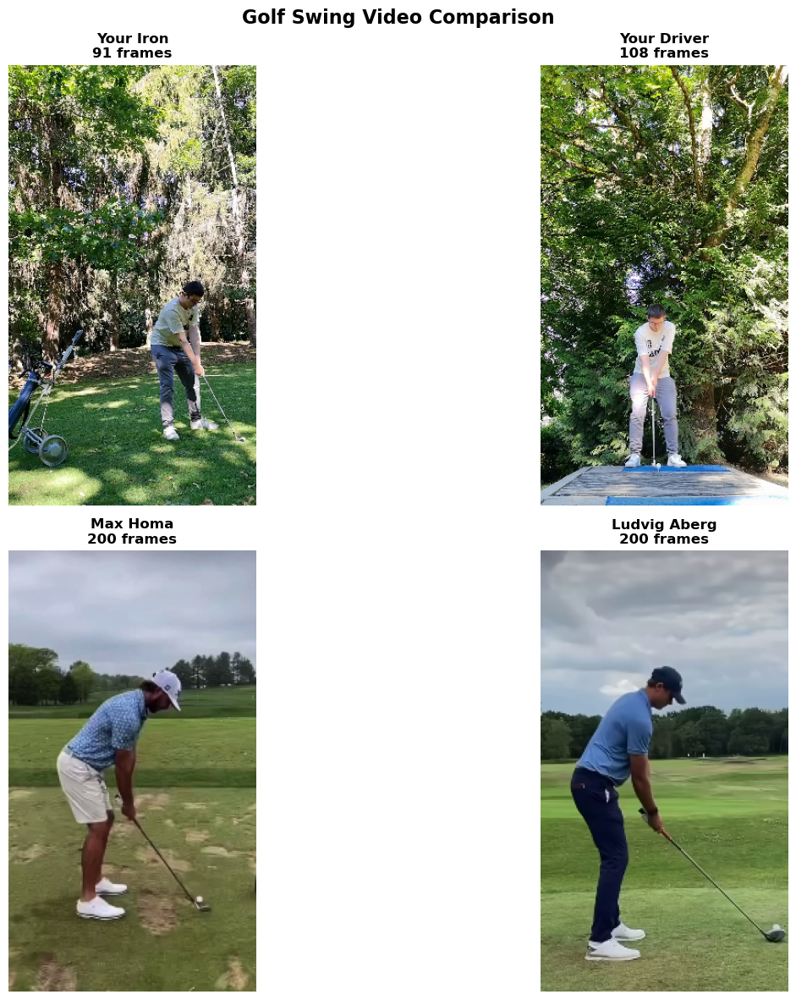

In [58]:
# Part 1: Side-by-side video comparison
def create_video_grid():
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Golf Swing Video Comparison', fontsize=16, fontweight='bold')
    
    videos = [(video_iron, 'Your Iron'), (video_driver, 'Your Driver'), 
              (iron_reference, 'Max Homa'), (driver_reference, 'Ludvig Aberg')]
    
    for idx, (video_data, name) in enumerate(videos):
        ax = axes[idx//2, idx%2]
        if video_data is not None:
            frame = video_data[0][::4, ::4]  # First frame, downsampled
            ax.imshow(frame)
            ax.set_title(f'{name}\n{len(video_data)} frames', fontweight='bold')
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

create_video_grid()

🎥 Processing video_0...
📊 video_0 shape: (91, 1920, 1080, 3)
✅ Extracted 90 frames of motion data from video_0
🎥 Processing video_1...
📊 video_1 shape: (108, 1920, 1080, 3)
✅ Extracted 107 frames of motion data from video_1
🎥 Processing video_2...
📊 video_2 shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from video_2
🎥 Processing video_3...
📊 video_3 shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from video_3


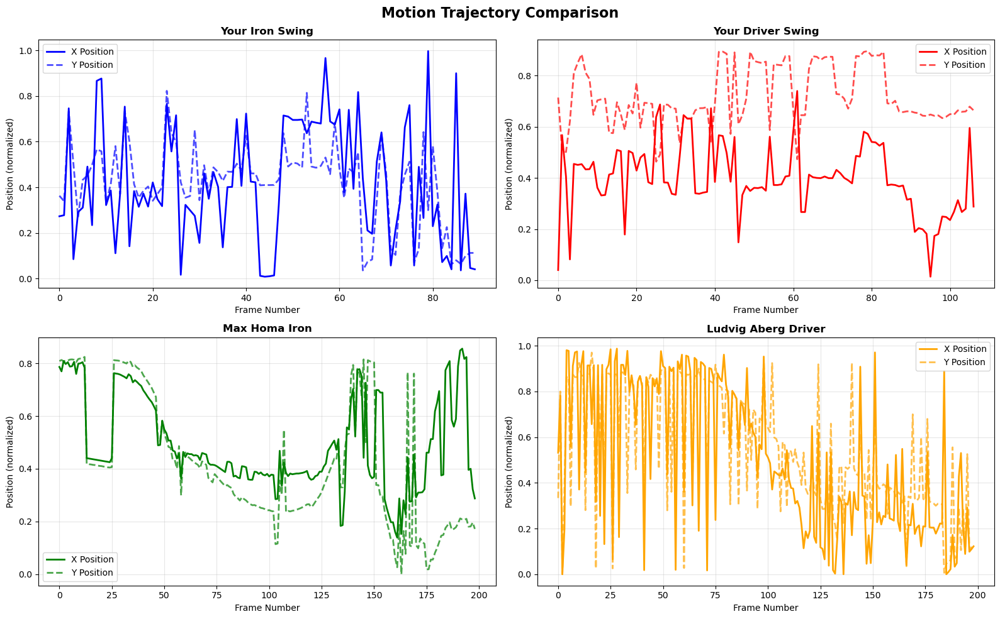

In [61]:
# Part 2: Motion trajectory comparison
def create_motion_trajectories():
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('Motion Trajectory Comparison', fontsize=16, fontweight='bold')
    
    videos = [
        (video_iron, 'Your Iron Swing'),
        (video_driver, 'Your Driver Swing'), 
        (iron_reference, 'Max Homa Iron'),
        (driver_reference, 'Ludvig Aberg Driver')
    ]
    
    colors = ['blue', 'red', 'green', 'orange']
    
    for idx, (video_data, name) in enumerate(videos):
        ax = axes[idx//2, idx%2]
        
        if video_data is not None:
            # Extract motion data
            frame_data = extract_frame_data_from_video(video_data, f'video_{idx}')
            
            # Plot X and Y trajectories
            ax.plot(frame_data[:, 0], label='X Position', color=colors[idx], linewidth=2)
            ax.plot(frame_data[:, 1], label='Y Position', color=colors[idx], 
                   linewidth=2, linestyle='--', alpha=0.7)
            
            ax.set_title(name, fontweight='bold')
            ax.set_xlabel('Frame Number')
            ax.set_ylabel('Position (normalized)')
            ax.legend()
            ax.grid(True, alpha=0.3)
        else:
            ax.text(0.5, 0.5, 'No Data', ha='center', va='center', transform=ax.transAxes)
    
    plt.tight_layout()
    plt.show()

create_motion_trajectories()

🎥 Processing Your Iron Swing...
📊 Your Iron Swing shape: (91, 1920, 1080, 3)
✅ Extracted 90 frames of motion data from Your Iron Swing
🎥 Processing Your Driver Swing...
📊 Your Driver Swing shape: (108, 1920, 1080, 3)
✅ Extracted 107 frames of motion data from Your Driver Swing
🎥 Processing Max Homa Iron...
📊 Max Homa Iron shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from Max Homa Iron
🎥 Processing Ludvig Aberg Driver...
📊 Ludvig Aberg Driver shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from Ludvig Aberg Driver


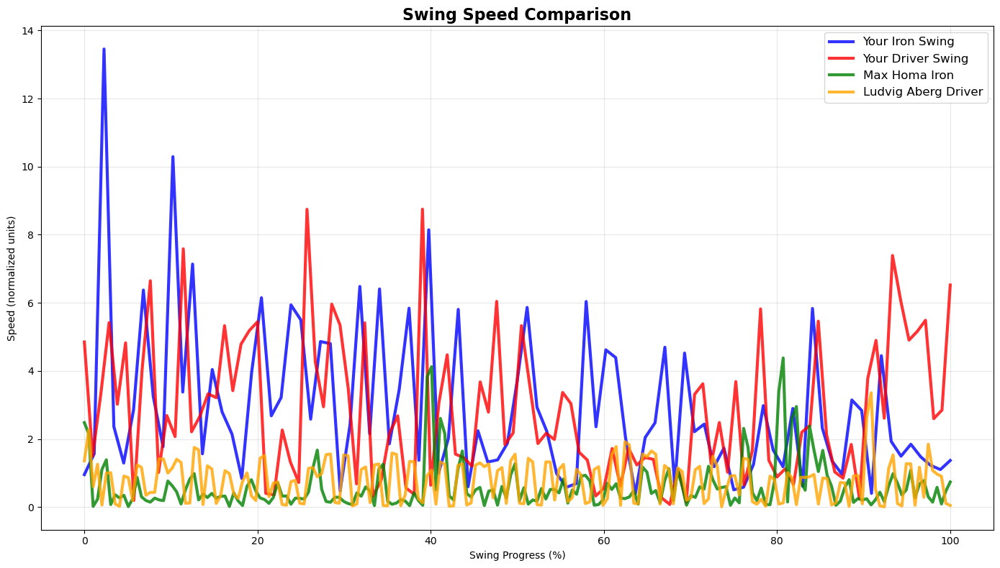

In [62]:
# Part 3: Speed comparison
def create_speed_comparison():
    fig, ax = plt.subplots(1, 1, figsize=(14, 8))
    ax.set_title('Swing Speed Comparison', fontsize=16, fontweight='bold')
    
    videos = [
        (video_iron, 'Your Iron Swing', 'blue'),
        (video_driver, 'Your Driver Swing', 'red'), 
        (iron_reference, 'Max Homa Iron', 'green'),
        (driver_reference, 'Ludvig Aberg Driver', 'orange')
    ]
    
    for video_data, name, color in videos:
        if video_data is not None:
            frame_data = extract_frame_data_from_video(video_data, name)
            
            if len(frame_data) > 1:
                # Calculate speed
                speed = np.sqrt(np.sum(np.diff(frame_data, axis=0)**2, axis=1))
                
                # Normalize to percentage of swing
                progress = np.linspace(0, 100, len(speed))
                
                ax.plot(progress, speed, label=name, color=color, linewidth=3, alpha=0.8)
    
    ax.set_xlabel('Swing Progress (%)')
    ax.set_ylabel('Speed (normalized units)')
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

create_speed_comparison()

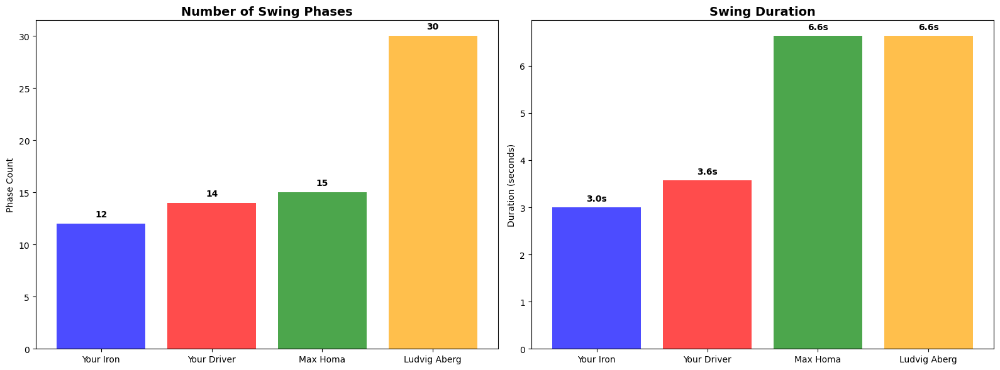

In [63]:
# Part 4: Phase comparison bar chart
def create_phase_comparison():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Phase count comparison
    phase_counts = [
        analysis_results.get('video_iron', {}).get('total_phases', 0),
        analysis_results.get('video_driver', {}).get('total_phases', 0),
        analysis_results.get('iron_reference', {}).get('total_phases', 0),
        analysis_results.get('driver_reference', {}).get('total_phases', 0)
    ]
    
    names = ['Your Iron', 'Your Driver', 'Max Homa', 'Ludvig Aberg']
    colors = ['blue', 'red', 'green', 'orange']
    
    bars1 = ax1.bar(names, phase_counts, color=colors, alpha=0.7)
    ax1.set_title('Number of Swing Phases', fontweight='bold', fontsize=14)
    ax1.set_ylabel('Phase Count')
    
    # Add value labels on bars
    for bar, count in zip(bars1, phase_counts):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{count}', ha='center', va='bottom', fontweight='bold')
    
    # Duration comparison
    durations = [
        analysis_results.get('video_iron', {}).get('total_duration', 0),
        analysis_results.get('video_driver', {}).get('total_duration', 0),
        analysis_results.get('iron_reference', {}).get('total_duration', 0),
        analysis_results.get('driver_reference', {}).get('total_duration', 0)
    ]
    
    bars2 = ax2.bar(names, durations, color=colors, alpha=0.7)
    ax2.set_title('Swing Duration', fontweight='bold', fontsize=14)
    ax2.set_ylabel('Duration (seconds)')
    
    # Add value labels on bars
    for bar, duration in zip(bars2, durations):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{duration:.1f}s', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()

create_phase_comparison()

### 🧑‍🎓📹 Pro vs Student Swing Comparison by Phase (with Pose Overlay)

The `compare_swing_phases()` function visually compares each swing phase between a **student video** and a **pro reference video**, displaying side-by-side frames (optionally with pose landmarks).

#### 📦 Inputs:
- `student_video_path`, `pro_video_path`: Paths to fixed videos (with silent audio).
- `student_phases`, `pro_phases`: Dicts of frame ranges per phase (from `detect_swing_phases()`).
- `show_pose`: If `True`, overlays pose landmarks using MediaPipe.

#### 🧠 Core Logic:
- For each swing phase (e.g., `"Address"`, `"Impact"`):
  - Finds the middle frame of that phase for both student and pro.
  - Extracts and optionally annotates frames using MediaPipe Pose.
  - Converts BGR → RGB for display compatibility.

#### 🎨 Output:
- A multi-row Matplotlib figure with:
  - Left: Student frame for each phase.
  - Right: Pro frame for the same phase.
  - Optional pose overlay to help analyze alignment, posture, and joint positioning.

#### 🧹 Cleanup:
- Releases video capture resources and closes the MediaPipe model.

✅ Use this for **visual feedback and coaching**, making swing differences easy to spot phase-by-phase.


🎥 Processing video_0...
📊 video_0 shape: (91, 1920, 1080, 3)
✅ Extracted 90 frames of motion data from video_0
🎥 Processing video_1...
📊 video_1 shape: (108, 1920, 1080, 3)
✅ Extracted 107 frames of motion data from video_1
🎥 Processing video_2...
📊 video_2 shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from video_2
🎥 Processing video_3...
📊 video_3 shape: (200, 1280, 720, 3)
✅ Extracted 199 frames of motion data from video_3


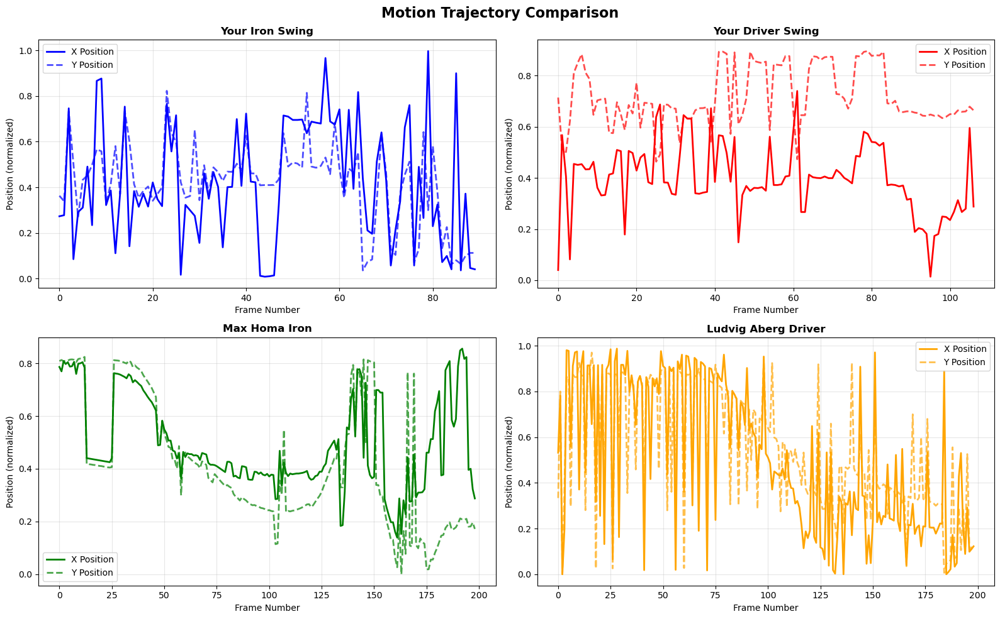

In [60]:
# Part 2: Motion trajectory comparison
def create_motion_trajectories():
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('Motion Trajectory Comparison', fontsize=16, fontweight='bold')
    
    videos = [
        (video_iron, 'Your Iron Swing'),
        (video_driver, 'Your Driver Swing'), 
        (iron_reference, 'Max Homa Iron'),
        (driver_reference, 'Ludvig Aberg Driver')
    ]
    
    colors = ['blue', 'red', 'green', 'orange']
    
    for idx, (video_data, name) in enumerate(videos):
        ax = axes[idx//2, idx%2]
        
        if video_data is not None:
            # Extract motion data
            frame_data = extract_frame_data_from_video(video_data, f'video_{idx}')
            
            # Plot X and Y trajectories
            ax.plot(frame_data[:, 0], label='X Position', color=colors[idx], linewidth=2)
            ax.plot(frame_data[:, 1], label='Y Position', color=colors[idx], 
                   linewidth=2, linestyle='--', alpha=0.7)
            
            ax.set_title(name, fontweight='bold')
            ax.set_xlabel('Frame Number')
            ax.set_ylabel('Position (normalized)')
            ax.legend()
            ax.grid(True, alpha=0.3)
        else:
            ax.text(0.5, 0.5, 'No Data', ha='center', va='center', transform=ax.transAxes)
    
    plt.tight_layout()
    plt.show()

create_motion_trajectories()

In [54]:


def compare_swing_phases(
    student_video_path, student_phases,
    pro_video_path, pro_phases,
    show_pose=True
):
    mp_pose = mp.solutions.pose
    pose = mp_pose.Pose(static_image_mode=True)
    mp_drawing = mp.solutions.drawing_utils
    mp_style = mp.solutions.drawing_styles

    def get_frame(cap, frame_idx, apply_pose=False):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()
        if not ret:
            raise ValueError(f"❌ Failed to read frame {frame_idx}")
        if apply_pose:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            results = pose.process(rgb)
            if results.pose_landmarks:
                mp_drawing.draw_landmarks(
                    frame,
                    results.pose_landmarks,
                    mp_pose.POSE_CONNECTIONS,
                    landmark_drawing_spec=mp_style.get_default_pose_landmarks_style()
                )
        return frame

    student_cap = cv2.VideoCapture(student_video_path)
    pro_cap = cv2.VideoCapture(pro_video_path)

    phase_names = list(student_phases.keys())
    num_phases = len(phase_names)

    plt.figure(figsize=(16, 6 * num_phases))

    for i, phase in enumerate(phase_names):
        # === Frame indices ===
        s_start, s_end = student_phases[phase]
        p_start, p_end = pro_phases[phase]

        s_middle = int((s_start + s_end) // 2)
        p_middle = int((p_start + p_end) // 2)

        # === Load frames ===
        student_frame = get_frame(student_cap, s_middle, apply_pose=show_pose)
        pro_frame = get_frame(pro_cap, p_middle, apply_pose=show_pose)

        student_rgb = cv2.cvtColor(student_frame, cv2.COLOR_BGR2RGB)
        pro_rgb = cv2.cvtColor(pro_frame, cv2.COLOR_BGR2RGB)

        # === Plot ===
        plt.subplot(num_phases, 2, 2*i+1)
        plt.imshow(student_rgb)
        plt.title(f"Student - {phase}")
        plt.axis("off")

        plt.subplot(num_phases, 2, 2*i+2)
        plt.imshow(pro_rgb)
        plt.title(f"Pro - {phase}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    student_cap.release()
    pro_cap.release()
    pose.close()


In [55]:
compare_swing_phases(
    student_video_path=video_iron_fixed,
    student_phases=phase_ranges_iron,
    pro_video_path=iron_reference_fixed,
    pro_phases=phase_ranges_iron_reference,
    show_pose=True  # Set to False to skip pose overlay
)


NameError: name 'phase_ranges_iron_reference' is not defined

In [47]:
compare_swing_phases(
    student_video_path=video_driver_fixed,
    student_phases=phase_ranges_driver,
    pro_video_path=driver_reference_fixed,
    pro_phases=phase_ranges_driver_reference,
    show_pose=True  # Set to False to skip pose overlay
)


NameError: name 'phase_ranges_driver' is not defined

### 🎥 Generate Annotated Debug Video with Swing Overlay and Slow Motion

This function `generate_debug_video_with_overlay()` creates a side-by-side **video+plot debug visualization**, showing real-time wrist motion trajectory alongside the actual video frames.

---

#### 🔁 Step-by-Step Workflow:

- **Frame-by-Frame Rendering**:
  - Reads each frame from the input video.
  - Overlays a Matplotlib plot of smoothed wrist Y-position (`smoothed`), marks current frame, swing start/end, and displays swing phase label (via `get_swing_phase_label()`).

- **Combined Output**:
  - Horizontally stacks video frame + debug plot.
  - Writes to an MP4 video using OpenCV (`cv2.VideoWriter`).

- **Plot Details**:
  - Flipped Y-axis for intuitive visualization.
  - Clear phase zones (`Address`, `Backswing`, etc.) shown with labels and color spans.

---

#### 🐢 Slow-Mo Re-encoding:
- After video is saved, re-encodes it using **FFmpeg** to:
  - Insert a slow-motion segment during the swing window (`swing_start` → `swing_end`).
  - Concatenate trimmed clips before, during (slowed), and after the swing.
  - Save to a more compatible format (`*_playable.mp4`).

---

#### 📤 Returns:
- A Colab-embedded video (`IPython.display.Video`) showing:
  - Original clip + live tracking plot.
  - Frame-wise swing phase.
  - Smooth debug overlay and swing window.

🎯 Perfect for **visual diagnostics**, **student feedback**, and **explaining biomechanics** with frame-accurate debug context.


In [64]:

# Get swing phase label for a given frame index
def get_swing_phase_label(frame_idx, phase_ranges):
    for label, (start, end) in phase_ranges.items():
        if start <= frame_idx <= end:
            return label
    return None

def generate_debug_video_with_overlay(
    video_filename: str,
    output_path: str,
    wrist_y: list,
    smoothed: list,
    phase_ranges: dict,
    swing_start: int,
    swing_end: int
):
    import gc
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
    from matplotlib import use as mpl_use
    mpl_use("Agg")  # ✅ For headless backend in Colab

    cap = cv2.VideoCapture(video_filename)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"📹 Frame resolution: {width}x{height}, FPS: {fps:.2f}, Total frames: {total_frames}")

    plot_width = int(width * 2.0)
    output_size = (width + plot_width, height)

    # ✅ Use mp4v codec for writing temporary mp4
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, output_size)

    fig, ax = plt.subplots(figsize=(plot_width / 100.0, height / 100.0), dpi=100)
    canvas = FigureCanvas(fig)

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    frame_idx = 0
    print("🔄 Rendering video with overlaid debug plots...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or frame is None:
            break

        if frame_idx >= len(wrist_y):
            print(f"📌 Reached end of trajectory data at frame {frame_idx}.")
            break

        try:
            ax.clear()
            ax.plot(smoothed, label="Smoothed Wrist Y", linestyle='--', color='blue')
            ax.axvline(frame_idx, color='black', linestyle='-', label="Current Frame")

            # ✅ Phase label helper (you must define or import this)
            phase_label = get_swing_phase_label(frame_idx, phase_ranges)
            if phase_label:
                ax.text(0.02, 0.95, phase_label, transform=ax.transAxes,
                        fontsize=18, color='black', fontweight='bold',
                        verticalalignment='top', horizontalalignment='left',
                        bbox=dict(facecolor='white', alpha=0.7, boxstyle='round'))

            ax.axvspan(swing_start, swing_end, color='green', alpha=0.2, label="Swing Window")

            ax.set_title(f"Debug Plot (Frame {frame_idx})", fontsize=20)
            ax.set_xlabel("Frame", fontsize=16)
            ax.set_ylabel("Wrist Y Position", fontsize=16)
            ax.set_xlim(0, len(wrist_y))
            ax.set_ylim(np.nanmax(wrist_y) + 10, np.nanmin(wrist_y) - 10)
            ax.legend(fontsize=14)
            fig.tight_layout()
            canvas.draw()

            plot_img = np.frombuffer(canvas.buffer_rgba(), dtype=np.uint8).reshape(
                canvas.get_width_height()[1], canvas.get_width_height()[0], 4
            )[..., :3]

            plot_img = cv2.resize(plot_img, (plot_width, height))
            frame = cv2.resize(frame, (width, height))
            combined_frame = np.hstack((frame, plot_img))
            out.write(combined_frame)

            if frame_idx % 50 == 0:
                print(f"✅ Processed frame {frame_idx}/{total_frames}")

            frame_idx += 1
            gc.collect()

        except Exception as e:
            print(f"❌ Error at frame {frame_idx}: {e}")
            break

    cap.release()
    out.release()
    print(f"✅ Debug video saved as {output_path}")

    # === Re-encode with FFmpeg ===
    reencoded_path = output_path.replace(".mp4", "_playable.mp4")

    # Convert swing frame indices to seconds
    start_time = swing_start / fps
    end_time = swing_end / fps
    slow_factor = 2.0  # Adjust this factor as needed

    # FFmpeg slow-motion filter logic
    filter_complex = (
        f"[0:v]trim=0:{start_time:.3f},setpts=PTS-STARTPTS[v1];"
        f"[0:v]trim={start_time:.3f}:{end_time:.3f},setpts={slow_factor}*(PTS-STARTPTS)[v2];"
        f"[0:v]trim={end_time:.3f},setpts=PTS-STARTPTS[v3];"
        f"[v1][v2][v3]concat=n=3:v=1:a=0[outv]"
    )

    cmd = [
        "ffmpeg", "-y", "-i", output_path,
        "-filter_complex", filter_complex,
        "-map", "[outv]",
        "-vcodec", "libx264", "-crf", "23", "-preset", "veryfast",
        "-pix_fmt", "yuv420p",
        reencoded_path
    ]

    print("🎬 Re-encoding with slow-motion for Colab compatibility...")
    subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)


    # Optional: give disk a moment to flush
    time.sleep(1)

    return Video(reencoded_path, embed=True, width=960)


In [65]:
debug_video = generate_debug_video_with_overlay(video_iron_fixed, "iron_debug.mp4", wrist_y_iron, smoothed_iron, phase_ranges_iron, swing_start_iron, swing_end_iron)

debug_video


error: OpenCV(4.13.0) :-1: error: (-5:Bad argument) in function 'VideoCapture'
> Overload resolution failed:
>  - Expected 'filename' to be a str or path-like object
>  - VideoCapture() missing required argument 'apiPreference' (pos 2)
>  - Argument 'index' is required to be an integer
>  - VideoCapture() missing required argument 'apiPreference' (pos 2)
>  - VideoCapture() missing required argument 'apiPreference' (pos 2)


In [67]:
# First, check what type of data video_iron_fixed contains
print(f"Type of video_iron_fixed: {type(video_iron_fixed)}")
print(f"Value of video_iron_fixed: {video_iron_fixed}")

# If video_iron_fixed is a file path, verify it exists
import os
if isinstance(video_iron_fixed, str):
    if os.path.exists(video_iron_fixed):
        print("Video file exists")
    else:
        print("Video file does not exist")

# Corrected function call with proper error handling
try:
    # Ensure video_iron_fixed is a valid string path
    if isinstance(video_iron_fixed, str) and os.path.exists(video_iron_fixed):
        debug_video = generate_debug_video_with_overlay(
            video_iron_fixed, 
            "iron_debug.mp4", 
            wrist_y_iron, 
            smoothed_iron, 
            phase_ranges_iron, 
            swing_start_iron, 
            swing_end_iron
        )
        debug_video
    else:
        print("Error: video_iron_fixed is not a valid file path")
        # If video_iron_fixed is not a path, you may need to save it first
        # For example, if it's a video array, save it as a file first
        
except Exception as e:
    print(f"Error generating debug video: {e}")

Type of video_iron_fixed: <class 'numpy.ndarray'>
Value of video_iron_fixed: [[[[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  ...

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]]


 [[[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  ...

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]

  [[0 0 0]
   [0 0 0]
   [0 0 0]
   ...
   [0 0 0]
   [0 0 0]
   [0 0 0]]]


 [[[0

In [66]:
debug_video = generate_debug_video_with_overlay(video_driver_fixed, "iron_debug.mp4", wrist_y_driver, smoothed_driver, phase_ranges_driver, swing_start_driver, swing_end_driver)

debug_video


NameError: name 'wrist_y_driver' is not defined